In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import scipy.stats as stats
from functools import reduce
from pathlib import Path
from IPython.display import display

### 1. Carga de los archivos Excel
- Leemos los tres Excel y guardamos sus hojas en `excels_cargados`.
- Primero buscamos los Excel de la cátedra en la carpeta local `data/raw`. Por compatibilidad, también aceptamos la carpeta local antigua `notebooks/datos crudos`.
- En este bloque no filtramos, limpiamos ni unimos datos. Los siguientes bloques reutilizan esta carga.


In [2]:
archivos_excel = ["Totalizadores Planta 2020_2022.xlsx","Totalizadores Planta - 2021_2023.xlsx","Totalizadores Planta 2022_2023.xlsx"]
raiz_proyecto = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
carpetas_candidatas = [raiz_proyecto / 'data' / 'raw', raiz_proyecto / 'notebooks' / 'datos crudos']
carpeta = next((ruta for ruta in carpetas_candidatas if all((ruta / nombre).is_file() for nombre in archivos_excel)), None)
if carpeta is None:
    rutas = '\n- '.join(str(ruta) for ruta in carpetas_candidatas)
    raise FileNotFoundError(f'No se encontraron los tres Excel esperados en:\n- {rutas}')

excels_cargados = {}
for nombre_archivo in archivos_excel:
    excels_cargados[nombre_archivo] = pd.read_excel(carpeta / nombre_archivo, sheet_name=None)
print(f'Archivos cargados: {len(excels_cargados)}. Todavía no se aplicó limpieza.')


Archivos cargados: 3. Todavía no se aplicó limpieza.


### 2. Días registrados por archivo y año
- Contamos las fechas distintas de cada archivo, sin repetirlas entre sus hojas con DIA y HORA.
- Graficamos los archivos en las filas y los años en las columnas, antes de cualquier limpieza.
- Son días registrados, no necesariamente días con 25 lecturas completas. No sumamos archivos porque comparten fechas.
- La fila «Días que difieren» cuenta fechas presentes en al menos dos archivos con datos distintos en alguna hoja/columna común; cada fecha suma una sola vez por año.
- Comparamos todas las filas del día, no solo el cierre. Ignoramos el orden de filas, pero una lectura faltante o una cantidad distinta de copias sí cuenta como diferencia. No contamos hojas/columnas exclusivas de un archivo como diferencias de valores.
- La fila «Cierre de frío distinto» compara únicamente Frio (Kw) de Consolidado EE en todas las fechas compartidas. Acepta cualquier segundo válido del minuto 23:59. No usa las otras features ni redondea los consumos.
- Copias del mismo valor de cierre no crean una diferencia. Si alguna versión carece de cierre, tiene una lectura de Frío faltante o inválida, o tiene varios valores distintos a las 23:59, el día queda «No comparable», separado del conteo. Detalle disponible en `comparacion_cierres_frio`.
- «Lecturas distintas antes del cierre»: comparamos las filas excluyendo las 23:59. Cuenta cambios en valores de cualquier feature común, celdas faltantes, horarios o cantidad de filas; aunque ambos archivos tengan los mismos horarios, valores diferentes sí cuentan. Ignoramos el orden de filas y contamos cada fecha una vez.
- «Diferencias en sus cierres»: comparamos todas las features comunes de las filas de las 23:59, aunque también cambien otras horas. Incluye cambios de valores, faltantes o cantidad de filas de cierre. No exige que el resto del día sea idéntico.
- Las filas pueden superponerse: los cambios en el cierre se cuentan independientemente de los cambios de valores, horarios o faltantes del resto del día. Cada fecha cuenta una vez por fila; no deben sumarse las filas como si fueran categorías excluyentes.


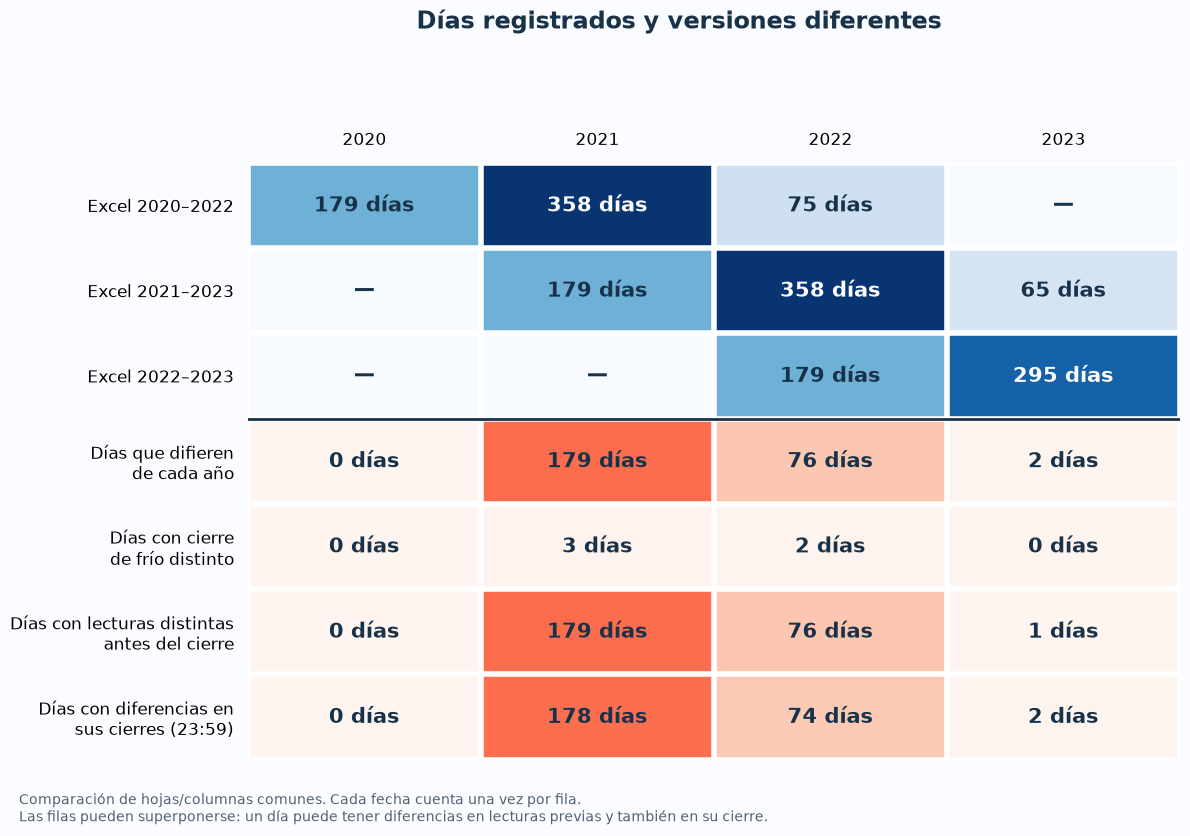

Cierres de frío no comparables (excluidos de su conteo): 2021: 3 días, 2022: 5 días, 2023: 2 días. Detalle en comparacion_cierres_frio.


In [3]:
PATRON_HORA_CIERRE = r'23:59(?::[0-5][0-9])?'

def es_hora_cierre(horas):
    return horas.astype(str).str.strip().str.fullmatch(PATRON_HORA_CIERRE)


fechas_por_archivo = {}
for nombre_archivo, hojas in excels_cargados.items():
    fechas_archivo = set()
    for df in hojas.values():
        if 'DIA' in df.columns and 'HORA' in df.columns:
            fechas_archivo.update(pd.to_datetime(df['DIA'], errors='coerce').dropna().dt.normalize())
    fechas_por_archivo[nombre_archivo] = pd.DatetimeIndex(sorted(fechas_archivo))

conteos = {nombre: pd.Series(fechas.year).value_counts() for nombre, fechas in fechas_por_archivo.items()}
dias_por_archivo_anio = pd.DataFrame.from_dict(conteos, orient='index').reindex(archivos_excel).fillna(0).astype(int).sort_index(axis=1)
# Comparamos hojas y columnas comunes; un cambio de esquema por sí solo no cuenta.
def firmas_por_dia(izquierda, derecha):
    columnas = sorted(set(izquierda.columns) & set(derecha.columns), key=str)
    juntas = pd.concat([izquierda[columnas], derecha[columnas]], ignore_index=True)
    fechas = pd.to_datetime(juntas['DIA'], errors='coerce').dt.normalize()
    juntas['HORA'] = juntas['HORA'].astype(str).str.strip()
    # Un dtype común evita diferencias artificiales entre, por ejemplo, 1 y 1.0.
    valores = juntas.drop(columns='DIA')
    hashes = pd.util.hash_pandas_object(valores, index=False)
    corte = len(izquierda)
    firmas = []
    for tramo in [slice(0, corte), slice(corte, None)]:
        tabla = pd.DataFrame({'Fecha': fechas.iloc[tramo], 'Firma': hashes.iloc[tramo]})
        firmas.append(tabla.groupby('Fecha')['Firma'].agg(lambda x: tuple(sorted(x))).to_dict())
    return firmas

import re

from scipy.optimize import linear_sum_assignment

def comparar_faltantes_cierre(a, b, columnas):
    if len(a) != len(b):
        return False, True  # Un cierre ausente o filas extra no son solo celdas faltantes.
    if a.empty:
        return False, False
    x, y = a[columnas].to_numpy(dtype=object), b[columnas].to_numpy(dtype=object)
    mx, my = pd.isna(x), pd.isna(y)
    x[mx], y[my] = 0, 0
    contradicciones = ((x[:, None, :] != y[None, :, :]) & ~mx[:, None, :] & ~my[None, :, :]).sum(axis=2)
    faltantes = (mx[:, None, :] != my[None, :, :]).sum(axis=2)
    peso = int(faltantes.max(initial=0) * len(x) + 1)
    filas, columnas_asignadas = linear_sum_assignment(contradicciones * peso + faltantes)
    return bool(faltantes[filas, columnas_asignadas].sum()), bool(contradicciones[filas, columnas_asignadas].sum())

def clasificar_diferencia_dia(a, b):
    cierre_a = a.loc[es_hora_cierre(a['HORA'])]
    cierre_b = b.loc[es_hora_cierre(b['HORA'])]
    firma_cierre_a, firma_cierre_b = firmas_por_dia(cierre_a, cierre_b)
    cierre_diferente = firma_cierre_a != firma_cierre_b
    # Comparamos todas las columnas comunes de las lecturas anteriores al cierre.
    previas_a = a.loc[~es_hora_cierre(a['HORA'])]
    previas_b = b.loc[~es_hora_cierre(b['HORA'])]
    firma_previas_a, firma_previas_b = firmas_por_dia(previas_a, previas_b)
    lecturas_previas_distintas = firma_previas_a != firma_previas_b
    columnas = sorted((set(a.columns) & set(b.columns)) - {'DIA', 'HORA'}, key=str)
    cierre_faltantes, cierre_incompatible = comparar_faltantes_cierre(cierre_a, cierre_b, columnas)
    grupos_a = {str(h).strip(): g for h, g in a.groupby(a['HORA'].astype(str).str.strip())}
    grupos_b = {str(h).strip(): g for h, g in b.groupby(b['HORA'].astype(str).str.strip())}
    horarios_distintos = {h: len(g) for h, g in grupos_a.items()} != {h: len(g) for h, g in grupos_b.items()}
    if horarios_distintos:
        return {'horarios': True, 'conflicto': False, 'fuera_cierre': True, 'cierre': cierre_diferente, 'cierre_faltantes': cierre_faltantes, 'cierre_incompatible': cierre_incompatible, 'lecturas_previas': lecturas_previas_distintas}
    conflicto, fuera_cierre = False, False
    for hora in grupos_a:
        x = grupos_a[hora][columnas].to_numpy(dtype=object)
        y = grupos_b[hora][columnas].to_numpy(dtype=object)
        mx, my = pd.isna(x), pd.isna(y)
        x[mx], y[my] = 0, 0
        presentes = ~mx[:, None, :] & ~my[None, :, :]
        contradicciones = ((x[:, None, :] != y[None, :, :]) & presentes).sum(axis=2)
        cambios = contradicciones + (mx[:, None, :] != my[None, :, :]).sum(axis=2)
        # Emparejamos las filas de la misma hora sin depender de su orden.
        peso = int(cambios.max(initial=0) * len(x) + 1)
        filas, columnas_asignadas = linear_sum_assignment(contradicciones * peso + cambios)
        conflicto |= bool(contradicciones[filas, columnas_asignadas].sum())
        if re.fullmatch(PATRON_HORA_CIERRE, hora) is None:
            fuera_cierre |= bool(cambios[filas, columnas_asignadas].sum())
    return {'horarios': False, 'conflicto': conflicto, 'fuera_cierre': fuera_cierre, 'cierre': cierre_diferente, 'cierre_faltantes': cierre_faltantes, 'cierre_incompatible': cierre_incompatible, 'lecturas_previas': lecturas_previas_distintas}

clasificacion_por_fecha = {}

dias_versiones_distintas = set()
for i, archivo_a in enumerate(archivos_excel):
    for archivo_b in archivos_excel[i + 1:]:
        fechas_compartidas = set(fechas_por_archivo[archivo_a]) & set(fechas_por_archivo[archivo_b])
        if not fechas_compartidas:
            continue
        hojas_a, hojas_b = excels_cargados[archivo_a], excels_cargados[archivo_b]
        for hoja in sorted(set(hojas_a) & set(hojas_b)):
            a, b = hojas_a[hoja], hojas_b[hoja]
            if not {'DIA', 'HORA'}.issubset(a.columns) or not {'DIA', 'HORA'}.issubset(b.columns):
                continue
            firmas_a, firmas_b = firmas_por_dia(a, b)
            fechas_diferentes = {fecha for fecha in fechas_compartidas if firmas_a.get(fecha, ()) != firmas_b.get(fecha, ())}
            dias_versiones_distintas.update(fechas_diferentes)
            if fechas_diferentes:
                grupos_a = dict(tuple(a.groupby(pd.to_datetime(a['DIA'], errors='coerce').dt.normalize())))
                grupos_b = dict(tuple(b.groupby(pd.to_datetime(b['DIA'], errors='coerce').dt.normalize())))
                for fecha in fechas_diferentes:
                    resultado = clasificar_diferencia_dia(grupos_a.get(fecha, a.iloc[:0]), grupos_b.get(fecha, b.iloc[:0]))
                    acumulado = clasificacion_por_fecha.setdefault(fecha, {'horarios': False, 'conflicto': False, 'fuera_cierre': False, 'cierre': False, 'cierre_faltantes': False, 'cierre_incompatible': False, 'lecturas_previas': False})
                    for clave in acumulado:
                        acumulado[clave] |= resultado[clave]

# Comparamos los cierres de Frío en todas las fechas compartidas, incluidos los casos no comparables.
cierres_por_archivo = {}
for archivo, hojas in excels_cargados.items():
    if 'Consolidado EE' not in hojas or not {'DIA', 'HORA', 'Frio (Kw)'}.issubset(hojas['Consolidado EE'].columns):
        raise ValueError(f"Falta DIA, HORA o Frio (Kw) en Consolidado EE de {archivo}")
    ee = hojas['Consolidado EE']
    fechas = pd.to_datetime(ee['DIA'], errors='coerce').dt.normalize()
    es_cierre = es_hora_cierre(ee['HORA'])
    cierres = pd.DataFrame({'Fecha': fechas[es_cierre], 'Frio': pd.to_numeric(ee.loc[es_cierre, 'Frio (Kw)'].astype(str).str.replace(',', '.', regex=False), errors='coerce')})
    cierres_por_archivo[archivo] = {fecha: grupo['Frio'].to_numpy() for fecha, grupo in cierres.groupby('Fecha')}

archivos_por_fecha = {}
for archivo, fechas in fechas_por_archivo.items():
    for fecha in fechas:
        archivos_por_fecha.setdefault(fecha, []).append(archivo)

comparaciones_cierre = []
for fecha, versiones in sorted(archivos_por_fecha.items()):
    if len(versiones) < 2:
        continue
    valores_cierre, motivos = {}, []
    for archivo in versiones:
        lecturas = cierres_por_archivo[archivo].get(fecha, np.array([]))
        distintos = np.unique(lecturas[np.isfinite(lecturas)])
        valores_cierre[archivo] = distintos.tolist()
        if len(lecturas) == 0:
            motivos.append(f'{archivo}: falta 23:59')
        elif not np.isfinite(lecturas).all():
            motivos.append(f'{archivo}: frío faltante o inválido')
        elif len(distintos) != 1:
            motivos.append(f'{archivo}: varios cierres contradictorios')
    if motivos:
        estado = 'No comparable'
    else:
        estado = 'Distinto' if len({v[0] for v in valores_cierre.values()}) > 1 else 'Igual'
    comparaciones_cierre.append({'Fecha': fecha, 'Estado': estado, 'Cierres por archivo': valores_cierre, 'Motivo': '; '.join(motivos)})
comparacion_cierres_frio = pd.DataFrame(comparaciones_cierre, columns=['Fecha', 'Estado', 'Cierres por archivo', 'Motivo'])
dias_cierre_distinto = {fila['Fecha'] for fila in comparaciones_cierre if fila['Estado'] == 'Distinto'}
dias_cierre_no_comparable = {fila['Fecha'] for fila in comparaciones_cierre if fila['Estado'] == 'No comparable'}
cierres_distintos_por_anio = pd.Series([fecha.year for fecha in dias_cierre_distinto], dtype='int64').value_counts().reindex(dias_por_archivo_anio.columns, fill_value=0)
assert dias_cierre_distinto.issubset(dias_versiones_distintas)

dias_lecturas_previas_distintas = {f for f, r in clasificacion_por_fecha.items() if r['lecturas_previas']}
dias_cierres_solo_faltantes = {f for f, r in clasificacion_por_fecha.items() if r['cierre_faltantes'] and not r['cierre_incompatible']}
dias_cierres_diferentes = {f for f, r in clasificacion_por_fecha.items() if r['cierre']}
# El cierre se evalúa independientemente de los cambios durante otras horas.
def contar_por_anio(fechas):
    return pd.Series([f.year for f in fechas], dtype='int64').value_counts().reindex(dias_por_archivo_anio.columns, fill_value=0)
assert dias_cierres_diferentes.issubset(dias_versiones_distintas)
assert dias_cierres_solo_faltantes.issubset(dias_cierres_diferentes)

dias_distintos_por_anio = pd.Series([fecha.year for fecha in dias_versiones_distintas], dtype='int64').value_counts().reindex(dias_por_archivo_anio.columns, fill_value=0)
cobertura_con_diferencias = dias_por_archivo_anio.copy()
cobertura_con_diferencias.loc['Días que difieren de cada año'] = dias_distintos_por_anio
cobertura_con_diferencias.loc['Cantidad de días con cierre de frío distinto'] = cierres_distintos_por_anio
cobertura_con_diferencias.loc['Días con lecturas distintas antes del cierre'] = contar_por_anio(dias_lecturas_previas_distintas)
cobertura_con_diferencias.loc['Días con diferencias en sus cierres (23:59)'] = contar_por_anio(dias_cierres_diferentes)
valores = cobertura_con_diferencias.to_numpy()
etiquetas_archivos = [nombre.replace('Totalizadores Planta', 'Excel').replace(' - ', ' ').replace('.xlsx', '').replace('_', '–') for nombre in dias_por_archivo_anio.index]
etiquetas_archivos.extend(['Días que difieren\nde cada año', 'Días con cierre\nde frío distinto', 'Días con lecturas distintas\nantes del cierre', 'Días con diferencias en\nsus cierres (23:59)'])
fig, ax = plt.subplots(figsize=(12, 8.5))
fig.patch.set_facecolor('#fafcff')
mascara_ultima_fila = np.zeros(valores.shape, dtype=bool)
mascara_ultima_fila[len(archivos_excel):, :] = True
ax.imshow(np.ma.masked_where(mascara_ultima_fila, valores), cmap='Blues', vmin=0, vmax=366, aspect='auto')
ax.imshow(np.ma.masked_where(~mascara_ultima_fila, valores), cmap='Reds', vmin=0, vmax=366, aspect='auto')
ax.set_xticks(range(len(dias_por_archivo_anio.columns)), dias_por_archivo_anio.columns, fontsize=12)
ax.xaxis.tick_top()
ax.set_yticks(range(len(etiquetas_archivos)), etiquetas_archivos, fontsize=12)
for i in range(valores.shape[0]):
    for j in range(valores.shape[1]):
        ax.text(j, i, f'{valores[i, j]} días' if valores[i, j] or i >= len(archivos_excel) else '—', ha='center', va='center', fontsize=15, fontweight='bold', color='white' if valores[i, j] > 200 else '#18324a')
ax.tick_params(length=0, pad=10)
for borde in ax.spines.values():
    borde.set_visible(False)
ax.set_xticks(np.arange(-.5, valores.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-.5, valores.shape[0], 1), minor=True)
ax.grid(which='minor', color='white', linewidth=4)
ax.tick_params(which='minor', length=0)
ax.axhline(len(archivos_excel) - .5, color='#18324a', linewidth=2)
fig.suptitle('Días registrados y versiones diferentes', fontsize=17, fontweight='bold', x=.57, y=.98, color='#18324a')
fig.text(.02, .025, 'Comparación de hojas/columnas comunes. Cada fecha cuenta una vez por fila.\nLas filas pueden superponerse: un día puede tener diferencias en lecturas previas y también en su cierre.', fontsize=10, color='#526171')
plt.tight_layout(rect=[0, .08, 1, .90])
plt.show()
if dias_cierre_no_comparable:
    no_comparables_por_anio = pd.Series([fecha.year for fecha in dias_cierre_no_comparable]).value_counts().sort_index()
    print('Cierres de frío no comparables (excluidos de su conteo): ' + ', '.join(f'{anio}: {cantidad} días' for anio, cantidad in no_comparables_por_anio.items()) + '. Detalle en comparacion_cierres_frio.')


### 2.1. Fechas compartidas por par de Excel

Cada celda muestra los días iguales o distintos sobre los días comparables. Los botones alternan entre el día completo y el cierre de `Frio (Kw)` de `Consolidado EE`. En el día completo se usan las hojas y columnas comunes; una fila ausente en una hoja común cuenta como diferencia. Para el cierre, se admiten horarios válidos del minuto `23:59` y se exige un solo valor numérico distinto por archivo y fecha, con todas sus lecturas de cierre válidas. Los días compartidos sin un cierre comparable se muestran aparte.


In [4]:
from io import BytesIO
from html import escape
import ipywidgets as widgets
from IPython.display import display

pares_excel = [(0, 1), (1, 2), (0, 2)]
anios_pares = [2020, 2021, 2022, 2023]
etiquetas_pares = [f'Archivo {i + 1} vs Archivo {j + 1}' for i, j in pares_excel]


cierres_por_excel = {
    archivo: pd.Series({
        fecha: lecturas[0]
        for fecha, lecturas in cierres.items()
        if np.isfinite(lecturas).all() and len(np.unique(lecturas)) == 1
    }, dtype=float)
    for archivo, cierres in cierres_por_archivo.items()
}
registros_pares = []
for (i, j), etiqueta_par in zip(pares_excel, etiquetas_pares):
    a, b = archivos_excel[i], archivos_excel[j]
    hojas_a, hojas_b = excels_cargados[a], excels_cargados[b]
    compartidos = set(fechas_por_archivo[a]) & set(fechas_por_archivo[b])
    dias_comparables, dias_distintos = set(), set()
    if compartidos:
        for hoja in hojas_a.keys() & hojas_b.keys():
            izquierda, derecha = hojas_a[hoja], hojas_b[hoja]
            comunes = set(izquierda.columns) & set(derecha.columns)
            if not {'DIA', 'HORA'}.issubset(comunes) or len(comunes) <= 2:
                continue
            firmas_a, firmas_b = firmas_por_dia(izquierda, derecha)
            fechas_hoja = compartidos & (firmas_a.keys() | firmas_b.keys())
            dias_comparables.update(fechas_hoja)
            dias_distintos.update(f for f in fechas_hoja if firmas_a.get(f, ()) != firmas_b.get(f, ()))

    frio_a, frio_b = cierres_por_excel[a], cierres_por_excel[b]
    cierres_comparables = compartidos & set(frio_a.index) & set(frio_b.index)
    cierres_distintos = {f for f in cierres_comparables if frio_a.loc[f] != frio_b.loc[f]}
    for modo, comparables, distintos in [('Todo el día', dias_comparables, dias_distintos),
                                        ('Cierre de Frío', cierres_comparables, cierres_distintos)]:
        for anio in anios_pares:
            total = sum(f.year == anio for f in compartidos)
            comparados = sum(f.year == anio for f in comparables)
            cambios = sum(f.year == anio for f in distintos)
            registros_pares.append({'Modo': modo, 'Año': anio, 'Par': etiqueta_par,
                                    'Compartidos': total, 'Comparables': comparados,
                                    'Distintos': cambios, 'Iguales': comparados - cambios,
                                    'No comparables': total - comparados})

comparacion_por_par = pd.DataFrame(registros_pares)
selector_resultado_pares = widgets.ToggleButtons(options=['Distintos', 'Iguales'])
selector_modo_pares = widgets.ToggleButtons(options=['Todo el día', 'Cierre de Frío'])
imagen_pares = widgets.Image(format='png', layout=widgets.Layout(width='100%', max_width='1100px'))


def actualizar_comparacion_por_par(_=None):
    modo = selector_modo_pares.value
    resultado = selector_resultado_pares.value
    datos = comparacion_por_par.loc[comparacion_por_par['Modo'].eq(modo)].set_index(['Año', 'Par'])
    proporciones = np.full((len(anios_pares), len(etiquetas_pares)), np.nan)
    etiquetas = {}
    for fila, anio in enumerate(anios_pares):
        for columna, par in enumerate(etiquetas_pares):
            dato = datos.loc[(anio, par)]
            if dato['Comparables']:
                proporciones[fila, columna] = dato[resultado] / dato['Comparables']
                texto = f"{dato[resultado]}/{dato['Comparables']}"
            else:
                texto = 'Sin comparables' if dato['Compartidos'] else 'Sin solapamiento'
            if dato['No comparables']:
                texto += f"\n{dato['No comparables']} no comparables"
            etiquetas[fila, columna] = texto

    with plt.ioff():
        fig, ax = plt.subplots(figsize=(10, 4.8), layout='constrained')
        try:
            mapa = plt.get_cmap('Oranges' if resultado == 'Distintos' else 'Blues')
            mapa.set_bad('#e9edf2')
            calor = ax.imshow(proporciones, cmap=mapa, vmin=0, vmax=1, aspect='auto')
            ax.set_xticks(range(len(etiquetas_pares)), etiquetas_pares)
            ax.xaxis.tick_top()
            ax.set_yticks(range(len(anios_pares)), anios_pares)
            ax.tick_params(length=0)
            ax.set_title(f'Días {resultado.lower()} · {modo}', pad=18)
            for (fila, columna), texto in etiquetas.items():
                color = 'white' if proporciones[fila, columna] >= .70 else '#1e293b'
                ax.text(columna, fila, texto, ha='center', va='center', color=color)
            fig.colorbar(calor, ax=ax, label='Proporción de días comparables')
            with BytesIO() as buffer:
                fig.savefig(buffer, format='png', dpi=120)
                imagen_pares.value = buffer.getvalue()
        finally:
            plt.close(fig)


selector_resultado_pares.observe(actualizar_comparacion_por_par, names='value')
selector_modo_pares.observe(actualizar_comparacion_por_par, names='value')
leyenda_pares = '<br>'.join(f'<b>Archivo {i}:</b> {escape(nombre)}' for i, nombre in enumerate(archivos_excel, 1))
actualizar_comparacion_por_par()
display(widgets.VBox([widgets.HTML(leyenda_pares), selector_resultado_pares, selector_modo_pares, imagen_pares]))


### 3. Diagnóstico de días con más de 25 filas
- Revisamos los días excedidos de cada hoja/archivo sin modificar los datos cargados.
- Primer gráfico: todos los valores de HORA repetidos dentro del mismo día, hoja y archivo, coincidan o no las demás columnas.
- Segundo gráfico: todos los valores de HORA fuera de los 25 horarios exactos esperados (00:00 a 23:00 y 23:59), incluyendo textos o vacíos si existen. Un desfase de segundos no implica por sí solo un error.
- Las barras cuentan días distintos: una fecha suma una vez por valor de hora aunque aparezca en varias hojas/archivos. Los valores repetidos y anómalos pueden coincidir.
- Guardamos los originales de los casos en `jornadas_detectadas` y su detalle en `detalle_jornadas`. El tratamiento se realiza después.


Días registrados: 1190 | Días con más de 25 filas: 16.


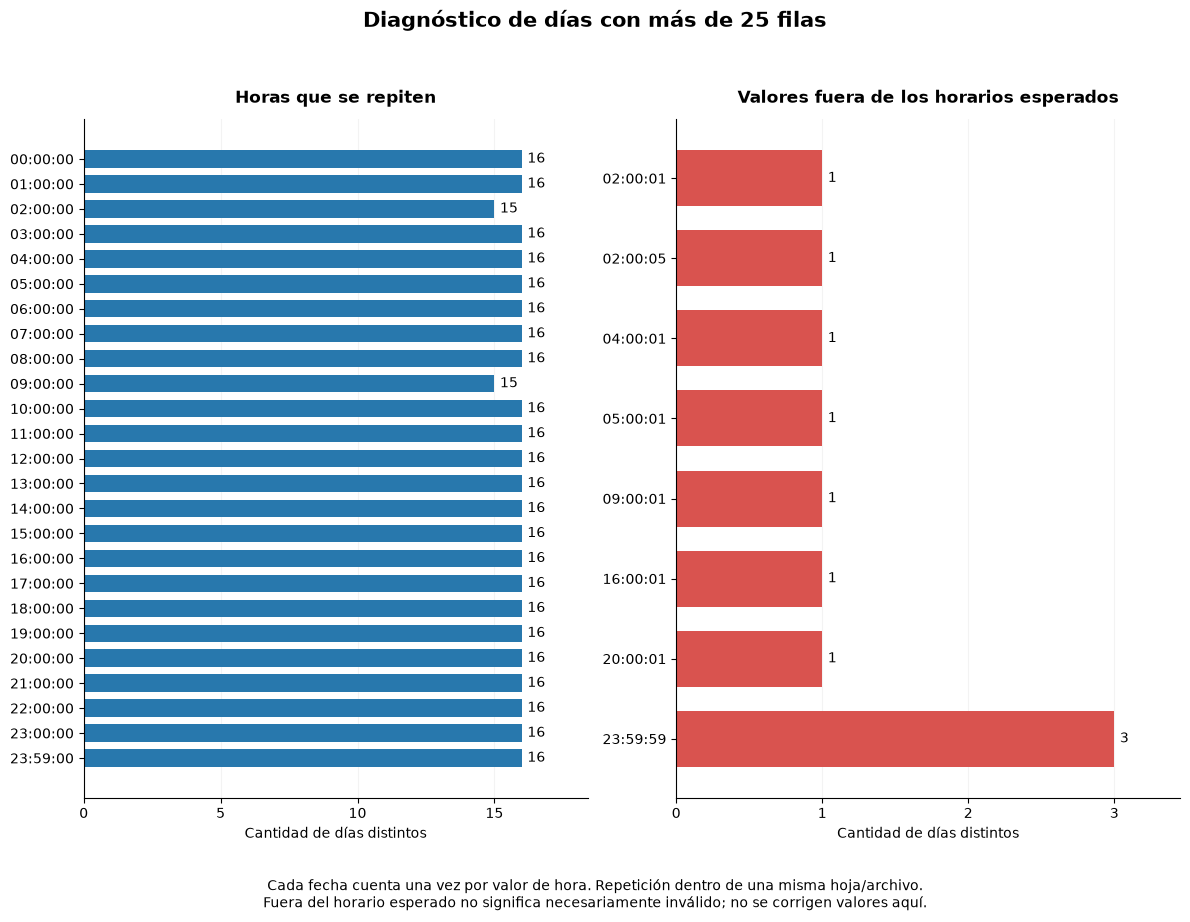

In [5]:
import re
from IPython.display import display

horas_normales = {f'{h:02d}:00:00' for h in range(24)} | {'23:59:00'}
registros_revision = []
horas_repetidas_por_dia, horas_anomalas_por_dia = set(), set()
jornadas_detectadas, fechas_registradas = {}, set()

def normalizar_hora(valor):
    if pd.isna(valor):
        return None
    texto = str(valor).strip()
    coincidencia = re.fullmatch(r'(\d{1,2}):(\d{2})(?::(\d{2}))?', texto)
    if not coincidencia:
        return None
    h, m, s = (int(v or 0) for v in coincidencia.groups())
    return f'{h:02d}:{m:02d}:{s:02d}' if h < 24 and m < 60 and s < 60 else None

def filas_sin_mediciones(dia):
    columnas = [c for c in dia.columns if c not in ['DIA', 'HORA']]
    return dia[columnas].apply(lambda c: c.isna() | c.map(lambda v: isinstance(v, str) and not v.strip())).all(axis=1) if columnas else pd.Series(False, index=dia.index)

for archivo, hojas in excels_cargados.items():
    for hoja, df in hojas.items():
        if 'DIA' not in df.columns or 'HORA' not in df.columns:
            continue
        fechas = pd.to_datetime(df['DIA'], errors='coerce').dt.normalize()
        fechas_registradas.update(fechas.dropna().unique())
        conteo = fechas.value_counts()
        for fecha, dia in df.loc[fechas.isin(conteo[conteo > 25].index)].groupby(fechas):
            jornadas_detectadas[(archivo, hoja, fecha)] = dia.copy()
            duplicadas = dia.duplicated(keep='first')
            vacias = filas_sin_mediciones(dia)
            horas = dia['HORA'].map(normalizar_hora)
            anomalas = ~horas.isin(horas_normales)
            etiquetas_hora = dia['HORA'].map(lambda v: '(vacío)' if pd.isna(v) or not str(v).strip() else str(v).strip())
            # Cuenta repetición de HORA, aunque las otras columnas sean idénticas o diferentes.
            claves_hora = horas.where(horas.notna(), etiquetas_hora)
            for valor in claves_hora[claves_hora.duplicated(keep=False)].unique():
                horas_repetidas_por_dia.add((fecha, valor))
            for valor in etiquetas_hora[anomalas].unique():
                horas_anomalas_por_dia.add((fecha, valor))
            registros_revision.append({'Archivo': archivo, 'Hoja': hoja, 'Fecha': fecha, 'Filas originales': len(dia), 'Copias sobrantes': int(duplicadas.sum()), 'Grupos duplicados': dia[dia.duplicated(keep=False)].drop_duplicates().shape[0], 'Filas sin mediciones': int(vacias.sum()), 'Filas con hora anómala': int(anomalas.sum())})

detalle_jornadas = pd.DataFrame(registros_revision)
dias_con_exceso = detalle_jornadas['Fecha'].nunique() if not detalle_jornadas.empty else 0
print(f'Días registrados: {len(fechas_registradas)} | Días con más de 25 filas: {dias_con_exceso}.')

def contar_dias_por_hora(pares):
    tabla = pd.DataFrame(sorted(pares), columns=['Fecha', 'Hora'])
    return tabla.groupby('Hora')['Fecha'].nunique().sort_index()

conteo_horas_repetidas = contar_dias_por_hora(horas_repetidas_por_dia)
conteo_horas_anomalas = contar_dias_por_hora(horas_anomalas_por_dia)
altura = max(4, 0.30 * max(len(conteo_horas_repetidas), len(conteo_horas_anomalas)) + 1.8)
fig, ejes = plt.subplots(1, 2, figsize=(12, altura))
for ax, conteos, titulo, color in [(ejes[0], conteo_horas_repetidas, 'Horas que se repiten', '#2878ad'), (ejes[1], conteo_horas_anomalas, 'Valores fuera de los horarios esperados', '#d9534f')]:
    if conteos.empty:
        ax.text(.5, .5, 'No se detectaron casos', ha='center', va='center', transform=ax.transAxes)
        ax.set_yticks([])
    else:
        barras = ax.barh(conteos.index, conteos.values, color=color, height=.7)
        ax.invert_yaxis()
        ax.bar_label(barras, padding=4, fontsize=10)
        ax.set_xlim(0, max(conteos.max() * 1.15, 1))
        ax.xaxis.get_major_locator().set_params(integer=True)
    ax.set_title(titulo, fontsize=12, fontweight='bold', pad=12)
    ax.set_xlabel('Cantidad de días distintos')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='x', alpha=.15)
    ax.set_axisbelow(True)
fig.suptitle('Diagnóstico de días con más de 25 filas', fontsize=15, fontweight='bold')
fig.text(.5, .015, 'Cada fecha cuenta una vez por valor de hora. Repetición dentro de una misma hoja/archivo.\nFuera del horario esperado no significa necesariamente inválido; no se corrigen valores aquí.', ha='center', fontsize=10)
plt.tight_layout(rect=[0, .07, 1, .95])
plt.show()


### 4. Tratamiento de los casos detectados
- Trabajamos con copias: los Excel cargados y el diagnóstico permanecen intactos.
- Quitamos duplicados exactos conservando una copia; quitamos filas sin mediciones solo si quedan exactamente los 25 horarios esperados.
- No corregimos automáticamente horas anómalas ni elegimos entre valores contradictorios.
- Si aún quedan más de 25 filas, guardamos el caso original en `jornadas_para_revisar` y lo excluimos de la unión por ahora. Los demás pasan a `datos_por_hoja`; tener hasta 25 filas no certifica su calidad.
- Este bloque prepara los datos; la unión ocurre en el siguiente.
- Conservamos también las tablas tratadas por archivo para comparar versiones antes de unirlas.


In [6]:
datos_por_hoja, jornadas_para_revisar, registro_tratamiento = {}, {}, []
datos_tratados_por_archivo = {}
for archivo, hojas in excels_cargados.items():
    for hoja, df in hojas.items():
        if 'DIA' not in df.columns or 'HORA' not in df.columns:
            continue
        fechas = pd.to_datetime(df['DIA'], errors='coerce').dt.normalize()
        fechas_exceso = [fecha for a, h, fecha in jornadas_detectadas if a == archivo and h == hoja]
        partes = [df.loc[~fechas.isin(fechas_exceso)].copy()]
        for fecha in fechas_exceso:
            original = jornadas_detectadas[(archivo, hoja, fecha)]
            limpio = original.drop_duplicates(keep='first').copy()
            sin_vacias = limpio.loc[~filas_sin_mediciones(limpio)]
            if len(sin_vacias) == 25 and set(sin_vacias['HORA'].map(normalizar_hora)) == horas_normales:
                limpio = sin_vacias.copy()
            conservar = len(limpio) <= 25
            if conservar:
                partes.append(limpio)
            else:
                jornadas_para_revisar[(archivo, hoja, fecha)] = original.copy()
            registro_tratamiento.append({'Archivo': archivo, 'Hoja': hoja, 'Fecha': fecha, 'Filas originales': len(original), 'Filas tras tratamiento': len(limpio), 'Estado': 'Conservar' if conservar else 'Revisar aparte'})
        preparado = pd.concat(partes).sort_index()
        preparado['DIA'] = pd.to_datetime(preparado['DIA'], errors='coerce').dt.normalize()
        preparado['HORA'] = preparado['HORA'].astype(str).str.strip()
        if not preparado.empty:
            datos_por_hoja.setdefault(hoja, []).append(preparado)
            datos_tratados_por_archivo.setdefault(archivo, {})[hoja] = preparado.copy()
detalle_tratamiento = pd.DataFrame(registro_tratamiento)
conservados = int((detalle_tratamiento['Estado'] == 'Conservar').sum()) if not detalle_tratamiento.empty else 0
print(f'Casos por archivo y hoja: {conservados} recuperados | {len(jornadas_para_revisar)} pendientes de revisión. Originales conservados.')


Casos por archivo y hoja: 0 recuperados | 338 pendientes de revisión. Originales conservados.


### 4.1. Comparación interactiva: features que más cambian entre versiones, después del tratamiento
- Comparamos todas las horas coincidentes de cada fecha entre archivos, en hojas y columnas comunes; no solo el cierre.
- Ordenamos las features por cantidad de días distintos con diferencias. La misma fecha cuenta una vez por feature, aunque tenga varias horas o pares de archivos diferentes.
- Rojo: valores presentes en ambas versiones que no coinciden. Amarillo: diferencias solo por faltantes en esa feature; si el día tiene ambos problemas, cuenta en rojo.
- Mostramos un solo gráfico con todas las variables que tienen 10 días o más con discrepancias, ordenadas de mayor a menor. El título indica cuántas variables cumplen el umbral. El detalle completo queda en `ranking_features`.
- Usamos únicamente los casos conservados por el punto 4. Los días apartados, las horas sin contraparte y las claves que aún tienen varias filas quedan fuera de esta comparación: no representan diferencias comprobadas de una feature alineada.
- Este ranking identifica dónde cambian los datos, no determina cuál versión es correcta ni qué variables predicen mejor el frío. Incluye metas e identificadores si difieren.

- Marcá dos o tres archivos: el ranking se recalcula solo con los pares seleccionados. Con menos de dos, se solicita completar la selección.
- Las etiquetas indican días con diferencias / días comparables y su porcentaje; un día comparable tiene al menos una hora alineada, no necesariamente una jornada completa. Dos nulos coinciden como ausencia, no prueban calidad.
- `ranking_features` contiene el resultado de la selección actual, incluso las features sin discrepancias. Sin fechas/horas comunes no hay evidencia para afirmar coincidencia.
- Al seleccionar tres archivos se unen las fechas comparables de sus pares; no se exige presencia simultánea en los tres. Las coberturas pueden cambiar entre selecciones.
- Requiere un kernel con `ipywidgets` (incluido en requirements.txt). Ejecutá primero los bloques 1 a 4 y luego esta celda.


In [7]:
def calcular_ranking_features(seleccionados):
    # Conservamos la procedencia antes de que la unión elija una versión.
    from collections import defaultdict
    
    dias_valores_distintos = defaultdict(set)
    dias_faltantes_distintos = defaultdict(set)
    dias_comparables_feature = defaultdict(set)
    tablas_comparables, claves_ambiguas = {}, set()
    for archivo, hojas in ((a, datos_tratados_por_archivo.get(a, {})) for a in seleccionados):
        tablas_comparables[archivo] = {}
        for hoja, df in hojas.items():
            tabla = df.loc[df['DIA'].notna()].copy()
            repetidas = tabla.duplicated(['DIA', 'HORA'], keep=False)
            for fecha, hora in tabla.loc[repetidas, ['DIA', 'HORA']].itertuples(index=False, name=None):
                claves_ambiguas.add((archivo, hoja, fecha, hora))
            # No elegimos arbitrariamente una fila cuando todavía quedan varias por hora.
            tablas_comparables[archivo][hoja] = tabla.loc[~repetidas].set_index(['DIA', 'HORA'])
    
    for i, archivo_a in enumerate(seleccionados):
        for archivo_b in seleccionados[i + 1:]:
            hojas_a = tablas_comparables.get(archivo_a, {})
            hojas_b = tablas_comparables.get(archivo_b, {})
            for hoja in sorted(set(hojas_a) & set(hojas_b)):
                a, b = hojas_a[hoja], hojas_b[hoja]
                claves = a.index.intersection(b.index)
                if claves.empty:
                    continue
                fechas = claves.get_level_values('DIA')
                for columna in sorted(set(a.columns) & set(b.columns), key=str):
                    feature = f'{columna} ({hoja})'
                    x, y = a.loc[claves, columna], b.loc[claves, columna]
                    x = x.mask(x.map(lambda v: isinstance(v, str) and not v.strip()))
                    y = y.mask(y.map(lambda v: isinstance(v, str) and not v.strip()))
                    presentes = x.notna() & y.notna()
                    distintos = presentes & ~x.eq(y).fillna(False)
                    faltantes = x.isna() ^ y.isna()
                    dias_comparables_feature[feature].update(fechas)
                    dias_valores_distintos[feature].update(fechas[distintos.to_numpy()])
                    dias_faltantes_distintos[feature].update(fechas[faltantes.to_numpy()])
    
    registros_ranking = []
    for feature in dias_comparables_feature:
        valores = dias_valores_distintos[feature]
        # Si ese día tiene ambos problemas, lo contamos solo en valores distintos.
        solo_faltantes = dias_faltantes_distintos[feature] - valores
        registros_ranking.append({'Feature': feature, 'Días con valores distintos': len(valores), 'Días solo con faltantes': len(solo_faltantes), 'Días con diferencias': len(valores | solo_faltantes), 'Días comparables': len(dias_comparables_feature[feature])})
    ranking_features = pd.DataFrame(registros_ranking, columns=['Feature', 'Días con valores distintos', 'Días solo con faltantes', 'Días con diferencias', 'Días comparables'])
    ranking_features = ranking_features.sort_values(['Días con diferencias', 'Feature'], ascending=[False, True]).reset_index(drop=True)
    
    ranking_features['% días con diferencias'] = (100 * ranking_features['Días con diferencias'] / ranking_features['Días comparables'])
    return ranking_features, len(claves_ambiguas)


from io import BytesIO
import ipywidgets as widgets
from IPython.display import display

minimo_dias_discrepancia = 10
casillas_archivos = [widgets.Checkbox(value=True, description=a, indent=False,
                    layout=widgets.Layout(width='auto')) for a in archivos_excel]
estado_ranking = widgets.Label(layout=widgets.Layout(width='auto'))
imagen_ranking = widgets.Image(format='png', layout=widgets.Layout(width='100%', max_width='1100px'))


def actualizar_ranking_features(change=None):
    global ranking_features
    seleccionados = [a for a, casilla in zip(archivos_excel, casillas_archivos) if casilla.value]
    imagen_ranking.layout.display = 'none'
    if len(seleccionados) < 2:
        ranking_features = pd.DataFrame()
        estado_ranking.value = 'Marcá al menos dos archivos para comparar.'
        return

    ranking_features, ambiguas = calcular_ranking_features(seleccionados)
    if ranking_features.empty:
        estado_ranking.value = 'No hay lecturas comparables para los archivos seleccionados.'
        return

    diferencias = ranking_features['Días con diferencias']
    datos = ranking_features.loc[diferencias >= minimo_dias_discrepancia]
    if datos.empty:
        estado_ranking.value = f'Ninguna variable tiene {minimo_dias_discrepancia} días o más con discrepancias.'
        return

    estado_ranking.value = (f'{len(datos)} de {len(ranking_features)} variables comparables tienen '
                           f'{minimo_dias_discrepancia} días o más con discrepancias. '
                           f'Claves ambiguas excluidas: {ambiguas}.')
    with plt.ioff():
        fig, ax = plt.subplots(figsize=(12, max(3.5, .34 * len(datos) + 1.8)), layout='constrained')
        try:
            posiciones = np.arange(len(datos))
            valores = datos['Días con valores distintos'].to_numpy()
            faltantes = datos['Días solo con faltantes'].to_numpy()
            ax.barh(posiciones, valores, color='#d9534f', label='Valores distintos')
            ax.barh(posiciones, faltantes, left=valores, color='#e9ad45', label='Solo faltantes')
            ax.set_yticks(posiciones, datos['Feature'], fontsize=9)
            ax.invert_yaxis()
            for posicion, (_, fila) in enumerate(datos.iterrows()):
                total, comparables = int(fila['Días con diferencias']), int(fila['Días comparables'])
                porcentaje = fila['% días con diferencias']
                ax.annotate(f'{total}/{comparables} ({porcentaje:.1f}%)', (total, posicion),
                            xytext=(5, 0), textcoords='offset points', va='center', fontsize=9)
            ax.set_xlim(0, datos['Días con diferencias'].max() * 1.3)
            ax.xaxis.get_major_locator().set_params(integer=True)
            ax.set_xlabel('Días con discrepancias')
            ax.set_title(f'Top {len(datos)} · Variables con {minimo_dias_discrepancia} días o más de discrepancias', fontweight='bold')
            ax.spines[['top', 'right']].set_visible(False)
            ax.grid(axis='x', alpha=.15)
            ax.set_axisbelow(True)
            ax.legend(loc='upper center', bbox_to_anchor=(.5, -.14), ncol=2, frameon=False)
            with BytesIO() as imagen:
                fig.savefig(imagen, format='png', dpi=120)
                imagen_ranking.value = imagen.getvalue()
        finally:
            plt.close(fig)
    imagen_ranking.layout.display = ''


for casilla in casillas_archivos:
    casilla.observe(actualizar_ranking_features, names='value')
actualizar_ranking_features()
display(widgets.VBox([widgets.HTML('<b>Elegí dos o tres archivos</b>'), *casillas_archivos,
                      estado_ranking, imagen_ranking]))


### 4.2. Diagnóstico de cierres antes de la unión

Estos chequeos reproducen las claves de hora exacta que usaba la unión antes de alinear los cierres. El primero cuenta cierres de Frío que el último Excel pisaría con un valor faltante o no numérico. El segundo muestra qué fechas tendrían varias filas de cierre al cruzar las hojas, con la hora, las hojas que aportaron esa fila y el Frío cuando está disponible. Una misma fecha puede aparecer en varias filas aunque tenga una sola medición de Frío.


In [8]:
claves_cierre = ['DIA', 'HORA']
ee_diagnostico = pd.concat(datos_por_hoja['Consolidado EE'], ignore_index=True)
es_cierre_ee = ee_diagnostico['HORA'].map(normalizar_hora).str.startswith('23:59:', na=False)
cierres_ee = ee_diagnostico.loc[es_cierre_ee & ee_diagnostico['DIA'].notna(), claves_cierre + ['Frio (Kw)']].copy()
cierres_ee['Frio_numerico'] = pd.to_numeric(
    cierres_ee['Frio (Kw)'].astype(str).str.replace(',', '.', regex=False), errors='coerce'
)
ganadores_cierre = cierres_ee.drop_duplicates(claves_cierre, keep='last')
cierres_recuperables = (
    cierres_ee.loc[np.isfinite(cierres_ee['Frio_numerico']), claves_cierre + ['Frio_numerico']]
    .drop_duplicates(claves_cierre, keep='last')
    .rename(columns={'Frio_numerico': 'Frio_recuperable'})
)
comparacion_desempate = ganadores_cierre.merge(cierres_recuperables, on=claves_cierre, how='left')
cierres_perdidos = comparacion_desempate.loc[
    ~np.isfinite(comparacion_desempate['Frio_numerico']) & comparacion_desempate['Frio_recuperable'].notna()
].sort_values(claves_cierre)
print(f'Cierres de Frío que se perderían con el desempate por hora exacta: {len(cierres_perdidos)}')
if not cierres_perdidos.empty:
    display(cierres_perdidos[claves_cierre + ['Frio (Kw)', 'Frio_recuperable']])


Cierres de Frío que se perderían con el desempate por hora exacta: 0


In [9]:
claves_por_hoja = []
for hoja, tablas in datos_por_hoja.items():
    claves_hoja = pd.concat([tabla[claves_cierre] for tabla in tablas], ignore_index=True)
    es_cierre = claves_hoja['HORA'].astype(str).str.startswith('23:59')
    claves_por_hoja.append(claves_hoja.loc[es_cierre].dropna(subset=['DIA']).drop_duplicates().assign(Hoja=hoja))

filas_cierre_originales = (
    pd.concat(claves_por_hoja, ignore_index=True)
    .groupby(claves_cierre, as_index=False)['Hoja']
    .agg(', '.join)
)
cierres_duplicados = filas_cierre_originales.loc[filas_cierre_originales['DIA'].duplicated(keep=False)]
cierres_duplicados = cierres_duplicados.merge(
    ganadores_cierre[claves_cierre + ['Frio_numerico']], on=claves_cierre, how='left', validate='one_to_one'
).sort_values(claves_cierre)
print(f'Fechas con varias filas de cierre antes de alinear horarios: {cierres_duplicados["DIA"].nunique()}')
if not cierres_duplicados.empty:
    display(cierres_duplicados)


Fechas con varias filas de cierre antes de alinear horarios: 13


,DIA,HORA,Hoja,Frio_numerico
0,2020-08-12,23:59:00,Auxiliar,NaN
1,2020-08-12,23:59:01,"Consolidado KPI, Consolidado Produccion, Total...",29964.0
2,2020-08-13,23:59:00,"Consolidado KPI, Consolidado Produccion, Total...",31421.0
3,2020-08-13,23:59:01,Auxiliar,NaN
4,2020-08-25,23:59:00,Auxiliar,NaN
5,2020-08-25,23:59:01,"Consolidado KPI, Consolidado Produccion, Total...",37809.0
6,2020-08-26,23:59:00,"Consolidado KPI, Consolidado Produccion, Total...",32562.0
7,2020-08-26,23:59:01,Auxiliar,NaN
8,2020-10-08,23:59:00,Auxiliar,NaN
9,2020-10-08,23:59:01,"Consolidado KPI, Consolidado Produccion, Total...",30220.0


### 5. Unión de archivos y hojas

Antes de cruzar las hojas, alineamos los cierres del minuto `23:59` usando `23:59:00` como hora común. Por ejemplo, el 12/08/2020 `Consolidado EE` registró Frío a las `23:59:01` y `Auxiliar` usó `23:59:00`. El ajuste permite que sus datos queden en la misma fila, cada uno en su propia columna.

La normalización se aplica a cada hoja de cada Excel del punto 4. Se guardan las horas originales ajustadas en `auditoria_cierres`. Las horas inválidas, como `23:59:99`, se registran para revisión en `cierres_invalidos`.

**Cómo volver a ejecutar.** Si el punto 4 ya está ejecutado en este kernel, podés correr desde el punto 5 en adelante con los Excel que quedaron en memoria. Si reiniciaste el kernel, ejecutá primero los puntos 1 a 4.

**Si hay cierres en conflicto.** Consultá `cierres_en_conflicto` para ver la fecha, la hoja, las horas originales y los valores que discrepan dentro de un Excel. El cruce continúa dejando esas columnas como faltantes en el cierre de ese archivo. Si esa fila gana el desempate y el conflicto es de Frío, su valor queda sin etiqueta para el día anterior.


In [10]:
def normalizar_cierres_hoja(tabla, hoja, orden):
    horas = tabla['HORA'].map(normalizar_hora)
    es_cierre = horas.str.startswith('23:59:', na=False) & tabla['DIA'].notna()
    invalidos = tabla['HORA'].astype(str).str.strip().str.startswith('23:59') & horas.isna()
    claves = ['DIA', 'HORA']
    auditados = tabla.loc[es_cierre & tabla['HORA'].ne('23:59:00'), claves]
    rechazados = tabla.loc[invalidos, claves]

    cierres = tabla.loc[es_cierre].copy()
    cierres['HORA'] = '23:59:00'
    repetidos = cierres['DIA'].duplicated(keep=False)
    partes = [tabla.loc[~es_cierre], cierres.loc[~repetidos]]
    combinados, conflictos = [], []
    columnas = tabla.columns.difference(claves, sort=False)
    for fecha, grupo in cierres.loc[repetidos].groupby('DIA'):
        valores = grupo[columnas].replace(r'^\s*$', np.nan, regex=True)
        distintos = valores.nunique(dropna=True)
        columnas_en_conflicto = distintos.index[distintos.gt(1)].tolist()
        if columnas_en_conflicto:
            conflictos.append({'Hoja': hoja, 'Orden en la hoja': orden, 'DIA': fecha,
                               'Horas originales': tabla.loc[grupo.index, 'HORA'].tolist(),
                               'Columnas en conflicto': columnas_en_conflicto,
                               'Valores en conflicto': {col: valores[col].dropna().unique().tolist()
                                                        for col in columnas_en_conflicto}})
        fila = valores.ffill().iloc[-1].to_dict()
        for columna in columnas_en_conflicto:
            fila[columna] = np.nan
        fila.update(DIA=fecha, HORA='23:59:00')
        combinados.append(fila)

    if combinados:
        partes.append(pd.DataFrame(combinados, columns=tabla.columns))
    return pd.concat(partes, ignore_index=True), auditados, rechazados, conflictos


dfs_listos_para_cruzar = []
horas_ajustadas, horas_invalidas, conflictos_cierre = [], [], []
for nombre_hoja, lista_dfs in datos_por_hoja.items():
    tablas = []
    for orden, tabla in enumerate(lista_dfs, start=1):
        tratada, ajustes, invalidas, conflictos = normalizar_cierres_hoja(tabla, nombre_hoja, orden)
        tablas.append(tratada)
        horas_ajustadas.append(ajustes.assign(Hoja=nombre_hoja, Orden_en_la_hoja=orden))
        horas_invalidas.append(invalidas.assign(Hoja=nombre_hoja, Orden_en_la_hoja=orden))
        conflictos_cierre.extend(conflictos)

    df_hoja_completa = pd.concat(tablas, ignore_index=True)
    # Para cada DIA y HORA tomamos, columna por columna, el último valor presente según el orden de carga.
    # Si el Excel más reciente trae la celda vacía, se conserva el valor del Excel anterior.
    df_hoja_completa = (df_hoja_completa.groupby(['DIA', 'HORA'], sort=False, dropna=False)
                        .last().reset_index())
    renombres = {col: f'{col} ({nombre_hoja})' for col in df_hoja_completa.columns if col not in ('DIA', 'HORA')}
    dfs_listos_para_cruzar.append(df_hoja_completa.rename(columns=renombres))

if not dfs_listos_para_cruzar:
    raise ValueError('No hay hojas tratadas para cruzar. Ejecutá el punto 4.')

auditoria_cierres = pd.concat(horas_ajustadas, ignore_index=True).rename(columns={'HORA': 'Hora original'})
cierres_invalidos = pd.concat(horas_invalidas, ignore_index=True).rename(columns={'HORA': 'Hora original'})
cierres_en_conflicto = pd.DataFrame(conflictos_cierre)
print(f'Horas de cierre ajustadas: {len(auditoria_cierres)} | Horas de cierre inválidas: {len(cierres_invalidos)}')
if not cierres_en_conflicto.empty:
    display(cierres_en_conflicto)
    print(f'Cierres con conflictos: {len(cierres_en_conflicto)}. Los valores disputados se dejaron como faltantes.')

df_final = reduce(
    lambda izquierda, derecha: pd.merge(
        izquierda, derecha, on=['DIA', 'HORA'], how='outer', validate='one_to_one'
    ),
    dfs_listos_para_cruzar,
).sort_values(['DIA', 'HORA']).reset_index(drop=True)
print(f'Listo: {df_final.shape[0]} filas y {df_final.shape[1]} columnas.')


Horas de cierre ajustadas: 231 | Horas de cierre inválidas: 0


,Hoja,Orden en la hoja,DIA,Horas originales,Columnas en conflicto,Valores en conflicto
0,Auxiliar,1,2021-07-01,"[23:59:59, 23:59:00]",[ .1],"{' .1': ['445610.999988', '445620.999306']}"


Cierres con conflictos: 1. Los valores disputados se dejaron como faltantes.


Listo: 29335 filas y 449 columnas.


Si coinciden varios cierres dentro de la misma hoja y el mismo Excel, se combinan los valores compatibles. Si una columna tiene valores presentes distintos, se registran en `cierres_en_conflicto` y la columna queda vacía en esa fila.

**Regla de desempate entre Excel.** Para cada `DIA`, `HORA` y columna de una hoja se conserva el valor del Excel más reciente (`2022_2023` > `2021_2023` > `2020_2022`). Si el más reciente tiene esa celda vacía, se usa el valor del anterior. Elegimos el más reciente porque cada exportación nueva del sistema incluye las correcciones hechas sobre los datos ya cargados; la tabla siguiente mide cuántas fechas compartidas cambian y cuántos cierres de Frío se recuperan del archivo anterior.

### 5.0. Justificación numérica de la regla de desempate

Comparamos el cierre de `Frio (Kw)` de `Consolidado EE` entre cada par de archivos, solo en las fechas que comparten. Un cierre es válido si es finito y está entre 0 y 1.000.000 kW. Consideramos iguales dos valores que difieren en menos de 0,5 kW.

In [11]:
def cierres_frio_por_archivo(archivo):
    tabla = datos_tratados_por_archivo.get(archivo, {}).get('Consolidado EE')
    if tabla is None or 'Frio (Kw)' not in tabla.columns:
        return pd.Series(dtype=float)
    es_cierre = tabla['HORA'].map(normalizar_hora).str.startswith('23:59:', na=False) & tabla['DIA'].notna()
    cierres = tabla.loc[es_cierre, ['DIA', 'Frio (Kw)']].copy()
    frio = pd.to_numeric(cierres['Frio (Kw)'].astype(str).str.replace(',', '.', regex=False), errors='coerce')
    cierres['Frio'] = frio.where(np.isfinite(frio) & frio.ge(0) & frio.lt(1_000_000))
    return cierres.groupby('DIA')['Frio'].last()


frio_por_archivo = {archivo: cierres_frio_por_archivo(archivo) for archivo in archivos_excel}
filas_desempate = []
for i, j in [(0, 1), (1, 2), (0, 2)]:
    viejo, nuevo = frio_por_archivo[archivos_excel[i]], frio_por_archivo[archivos_excel[j]]
    comunes = viejo.index.intersection(nuevo.index)
    v, n = viejo.loc[comunes], nuevo.loc[comunes]
    ambos_validos = v.notna() & n.notna()
    diferencia = (n - v).abs()[ambos_validos]
    distintos = diferencia.gt(0.5)
    filas_desempate.append({
        'Par (anterior → reciente)': f'Archivo {i + 1} → Archivo {j + 1}',
        'Fechas compartidas': len(comunes),
        'Mismo valor': int((~distintos).sum()),
        'Valores distintos': int(distintos.sum()),
        'Mediana |dif.| (kW)': float(diferencia[distintos].median()) if distintos.any() else 0.0,
        'Solo el reciente es válido': int((n.notna() & v.isna()).sum()),
        'Solo el anterior es válido': int((v.notna() & n.isna()).sum()),
        'Ninguno válido': int((v.isna() & n.isna()).sum()),
    })

desempate = pd.DataFrame(filas_desempate).set_index('Par (anterior → reciente)')
display(desempate)

total_compartidas = desempate['Fechas compartidas'].sum()
total_distintos = desempate['Valores distintos'].sum()
print(f'Fechas compartidas con valores distintos: {total_distintos} de {total_compartidas} '
      f'({total_distintos / max(total_compartidas, 1):.1%}).')
print(f"Cierres que solo el archivo reciente trae válidos: {desempate['Solo el reciente es válido'].sum()}")
print(f"Cierres que solo el archivo anterior trae válidos: {desempate['Solo el anterior es válido'].sum()} "
      '(la unión los recupera porque toma el último valor presente).')

,Fechas compartidas,Mismo valor,Valores distintos,Mediana |dif.| (kW),Solo el reciente es válido,Solo el anterior es válido,Ninguno válido
Par (anterior → reciente),,,,,,,
Archivo 1 → Archivo 2,248,243,1,32768.0,4,0,0
Archivo 2 → Archivo 3,240,240,0,0.0,0,0,0
Archivo 1 → Archivo 3,0,0,0,0.0,0,0,0


Fechas compartidas con valores distintos: 1 de 488 (0.2%).
Cierres que solo el archivo reciente trae válidos: 4
Cierres que solo el archivo anterior trae válidos: 0 (la unión los recupera porque toma el último valor presente).


### 5.1. Versionado del dataset unificado inicial

Guardamos el `df_final` del punto 5 en `data/dataset_unificado_inicial.csv` justo después del cruce de hojas, antes de convertir las columnas de medición a números o filtrar los cierres. Calculamos el SHA-256 leyendo ese CSV por bloques y registramos la huella en `data/checksums.json` con su ruta relativa al repositorio.

Usamos SHA-256 porque MD5 tiene colisiones conocidas. La huella verifica que dos ejecuciones produjeron un archivo con los mismos bytes.

Preprocesamiento genera otro archivo, `data/processed/dataset_final.csv`. Su huella se agrega al mismo JSON con su propia ruta cuando se exporta el dataset final. Cada bloque actualiza solo la entrada de su archivo.

Para compartir este paso por GitHub, versionamos el notebook y el JSON de huellas. El CSV inicial se genera localmente a partir de los Excel y está en `.gitignore`.


In [12]:
import hashlib
import json
from pathlib import Path

carpeta_actual = Path.cwd().resolve()
raiz_proyecto = next(
    (ruta for ruta in (carpeta_actual, *carpeta_actual.parents)
     if (ruta / 'notebooks' / 'eda.ipynb').is_file()),
    None,
)
if raiz_proyecto is None:
    raise FileNotFoundError('Ejecutá el notebook desde la carpeta del proyecto o desde notebooks.')

ruta_inicial = raiz_proyecto / 'data' / 'dataset_unificado_inicial.csv'
ruta_checksums = raiz_proyecto / 'data' / 'checksums.json'
ruta_inicial.parent.mkdir(parents=True, exist_ok=True)

checksums = json.loads(ruta_checksums.read_text(encoding='utf-8')) if ruta_checksums.exists() else {}
if not isinstance(checksums, dict):
    raise ValueError('data/checksums.json debe contener un objeto con rutas y sus huellas.')

df_final.to_csv(ruta_inicial, index=False, encoding='utf-8', lineterminator='\n')
huella = hashlib.sha256()
with ruta_inicial.open('rb') as archivo:
    for bloque in iter(lambda: archivo.read(64 * 1024), b''):
        huella.update(bloque)

clave_inicial = ruta_inicial.relative_to(raiz_proyecto).as_posix()
checksums[clave_inicial] = huella.hexdigest()
ruta_checksums.write_text(json.dumps(checksums, indent=2, sort_keys=True) + '\n', encoding='utf-8')
print(f'{clave_inicial} | SHA-256: {checksums[clave_inicial]}')
print('Huella registrada en data/checksums.json')


data/dataset_unificado_inicial.csv | SHA-256: ae476695b73b0b27dff86cd8e182ba1d6d49d1b18515954306011b5360f84989
Huella registrada en data/checksums.json


Convertimos las comas en puntos y las columnas a flotantes

In [13]:
df_final.head()

,DIA,HORA,EE Planta / Hl (Consolidado KPI),EE Elaboracion / Hl (Consolidado KPI),EE Bodega / Hl (Consolidado KPI),EE Cocina / Hl (Consolidado KPI),EE Envasado / Hl (Consolidado KPI),EE Linea 2 / Hl (Consolidado KPI),EE Linea 3 / Hl (Consolidado KPI),EE Linea 4 / Hl (Consolidado KPI),...,.28 (Auxiliar),.29 (Auxiliar),.30 (Auxiliar),.31 (Auxiliar),Unnamed: 0 (Auxiliar),Unnamed: 3 (Auxiliar),Hl Linea 2 (Auxiliar),Ultimo Dato del Dia (Seguimiento Dia),Unnamed: 3 (Seguimiento Dia),Unnamed: 4 (Seguimiento Dia)
0,2020-07-01,00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN
1,2020-07-01,01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN
2,2020-07-01,02:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN
3,2020-07-01,03:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN
4,2020-07-01,04:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN


In [14]:
# 1. Identificar las columnas correctas explícitamente
columnas_a_float = [col for col in df_final.columns if col not in ['DIA', 'HORA']]

# 2. Reemplazar comas por puntos y convertir a numérico columna por columna
for col in columnas_a_float:
    # A. Nos aseguramos de tratar la columna como texto, y cambiamos ',' por '.'
    # Usamos regex=False porque es más rápido y exacto para buscar un simple caracter
    df_final[col] = df_final[col].astype(str).str.replace(',', '.', regex=False)
    
    # B. Forzamos la conversión a float. Si dice "N/A" o algo raro, se vuelve NaN
    df_final[col] = pd.to_numeric(df_final[col], errors='coerce')

# Opcional: Verificar que funcionó
print("Tipos de datos actualizados:")
print(df_final[columnas_a_float].dtypes.head(3)) # Muestra los tipos de las primeras 3 columnas

Tipos de datos actualizados:
EE Planta / Hl (Consolidado KPI)         float64
EE Elaboracion / Hl (Consolidado KPI)    float64
EE Bodega / Hl (Consolidado KPI)         float64
dtype: object


In [15]:
df_final.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 29335 entries, 0 to 29334
Data columns (total 449 columns):
 #    Column                                                    Non-Null Count  Dtype         
---   ------                                                    --------------  -----         
 0    DIA                                                       29334 non-null  datetime64[us]
 1    HORA                                                      29333 non-null  str           
 2    EE Planta / Hl (Consolidado KPI)                          28135 non-null  float64       
 3    EE Elaboracion / Hl (Consolidado KPI)                     28135 non-null  float64       
 4    EE Bodega / Hl (Consolidado KPI)                          28135 non-null  float64       
 5    EE Cocina / Hl (Consolidado KPI)                          25659 non-null  float64       
 6    EE Envasado / Hl (Consolidado KPI)                        28135 non-null  float64       
 7    EE Linea 2 / Hl (Consolidado KPI)       

### Hipótesis por hoja

Antes de mirar correlaciones, dejamos escrito qué esperamos de cada hoja. Las secciones siguientes las confirman o descartan.

| Hoja | Qué contiene | Hipótesis sobre el Frío del día siguiente |
|---|---|---|
| `Consolidado EE` | Energía eléctrica diaria por área (kW). Incluye `Frio (Kw)`, de donde sale el target. | El Frío de hoy es el mejor predictor de mañana (inercia de la planta). `Servicios` y `Sala Maq` agrupan equipos de frío, así que deberían correlacionar mucho con Frío y ser redundantes. |
| `Totalizadores Energia` | Medidores individuales: compresores Mycom, condensadores, bombas de glicol, trafos. | Los compresores, condensadores y bombas de glicol son parte del sistema de frío: casi copias del Frío del mismo día. |
| `Consolidado Produccion` / `Totalizadores Produccion` | Hl de mosto, cerveza producida, filtrada y envasada; cocimientos. | Más cocimientos y mosto hoy implican más carga de enfriamiento y fermentación en los días siguientes. |
| `Consolidado Agua` / `Totalizadores Agua` | Consumo de agua por área. | Indicador de actividad (cocción, limpiezas, envasado). Correlación positiva moderada. |
| `Consolidado GasVapor` / `Totalizadores Gas y Vapor` | Gas y vapor por área. | El calor de cocina y pasteurización hay que extraerlo después: relación indirecta. |
| `Totalizadores Glicol` | Circuitos de glicol de fermentación y reposo. | Relación directa con la demanda de frío de bodega. |
| `Consolidado Aire`, `Totalizadores CO2`, `Totalizadores Efluentes` | Servicios auxiliares. | Relación débil; el CO2 acompaña a la fermentación. |
| `Consolidado KPI` | Cocientes consumo/Hl y metas de gestión. | Son derivados de otras columnas o valores fijados por la empresa: no aportan mediciones nuevas. |
| `Auxiliar`, `Seguimiento Dia` | Hojas de control del archivo. | No son mediciones. |

Miramos los nulos de las columnas

In [16]:
nulos_por_columna = df_final.isna().sum()
# print(nulos_por_columna[nulos_por_columna > 0].sort_values(ascending=False))
print(nulos_por_columna[nulos_por_columna > 0].sort_values(ascending=False).to_string())

 .29 (Auxiliar)                                             29335
 .30 (Auxiliar)                                             29335
 .31 (Auxiliar)                                             29335
Unnamed: 3 (Auxiliar)                                       29335
Unnamed: 35 (Consolidado KPI)                               29335
 .6 (Auxiliar)                                              29335
Unnamed: 22 (Consolidado KPI)                               29335
Unnamed: 21 (Consolidado KPI)                               29335
 .27 (Auxiliar)                                             29335
Unnamed: 123 (Consolidado KPI)                              29335
 .26 (Auxiliar)                                             29335
 .25 (Auxiliar)                                             29335
Unnamed: 46 (Consolidado KPI)                               29335
  (Consolidado KPI)                                         29335
 .4 (Auxiliar)                                              29335
 .3 (Auxil

### Cobertura del calendario y datos faltantes

Cada color indica el porcentaje de celdas faltantes entre todas las columnas de medición de la tabla unificada. Las flechas cambian el año y el selector cambia las horas esperadas.

- **Cierre 23:59:** una lectura esperada por día. Si el cierre falta, el día figura en violeta con 100%.
- **Lecturas horarias:** 24 lecturas esperadas (00:00 a 23:00). Cada hora ausente aporta una fila completa de faltantes. El violeta indica que no hay ninguna de las horas esperadas.
- **Gris:** día fuera del rango entre la primera y la última fecha observadas. El calendario muestra el año completo.
- Si dos formatos de `HORA` representan el mismo horario, se usa la última fila de ese horario en la tabla unificada. Las horas fuera de los horarios esperados quedan fuera del cálculo.

In [17]:
import calendar
import ipywidgets as widgets
from matplotlib.colors import Normalize
from matplotlib.patches import Patch, Rectangle


def calcular_cobertura_calendario(tabla):
    mediciones = tabla.columns.difference(['DIA', 'HORA'], sort=False)
    fechas = pd.to_datetime(tabla['DIA'], errors='coerce').dt.normalize()
    if not len(mediciones) or not fechas.notna().any():
        raise ValueError('La tabla necesita fechas y columnas de medición para calcular la cobertura.')

    horas = tabla['HORA'].map(normalizar_hora)
    claves = pd.DataFrame({'DIA': fechas, 'Hora': horas})
    # Dos formatos de una misma hora representan un solo horario esperado.
    indices_validos = claves.dropna().drop_duplicates(keep='last').index
    lecturas = claves.loc[indices_validos].assign(
        Presentes=tabla.loc[indices_validos, mediciones].notna().sum(axis=1)
    )
    resultados = {}
    for modo, horas_esperadas in {
        'Cierre 23:59': {'23:59:00'},
        'Lecturas horarias': {f'{h:02d}:00:00' for h in range(24)},
    }.items():
        seleccion = lecturas.loc[lecturas['Hora'].isin(horas_esperadas)]
        resumen = seleccion.groupby('DIA')['Presentes'].sum()
        total = len(mediciones) * len(horas_esperadas)
        resultados[modo] = pd.DataFrame({'Porcentaje': 100 * (total - resumen) / total})
    return fechas.min(), fechas.max(), resultados


inicio_cobertura, fin_cobertura, cobertura_por_modo = calcular_cobertura_calendario(df_final)
meses = ('Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio', 'Julio',
         'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre')


def graficar_calendario_cobertura(anio, modo):
    porcentajes = cobertura_por_modo[modo]['Porcentaje']
    colores = plt.get_cmap('YlOrRd')
    escala = Normalize(0, 100)
    sin_registro, fuera_cobertura = '#665298', '#e4e8ee'
    fig, ejes = plt.subplots(3, 4, figsize=(17, 10), layout='constrained')
    for mes, ax in enumerate(ejes.flat, 1):
        ax.set_title(meses[mes - 1], fontsize=13, fontweight='bold')
        ax.set_xlim(0, 7)
        ax.set_ylim(6, 0)
        ax.set_xticks(np.arange(7) + .5, ['Lu', 'Ma', 'Mi', 'Ju', 'Vi', 'Sá', 'Do'])
        ax.xaxis.tick_top()
        ax.tick_params(length=0, labelsize=8)
        ax.set_yticks([])
        ax.set_frame_on(False)
        for fila, semana in enumerate(calendar.Calendar().monthdayscalendar(anio, mes)):
            for columna, dia in enumerate(semana):
                if dia == 0:
                    continue
                fecha = pd.Timestamp(anio, mes, dia)
                porcentaje = porcentajes.get(fecha)
                if fecha < inicio_cobertura or fecha > fin_cobertura:
                    fondo, etiqueta, tinta = fuera_cobertura, '—', '#334155'
                elif porcentaje is None:
                    fondo, etiqueta, tinta = sin_registro, '100%', 'white'
                else:
                    fondo, etiqueta = colores(escala(porcentaje)), f'{porcentaje:.1f}%'
                    tinta = 'white' if porcentaje >= 72 else '#222222'
                ax.add_patch(Rectangle((columna, fila), 1, 1, facecolor=fondo, edgecolor='white'))
                ax.text(columna + .12, fila + .28, dia, color=tinta, fontsize=8, va='center')
                ax.text(columna + .5, fila + .70, etiqueta, color=tinta, fontsize=8, ha='center', va='center')
    fig.suptitle(f'{anio} · {modo} · valores faltantes por día', fontsize=17, fontweight='bold')
    fig.colorbar(plt.cm.ScalarMappable(norm=escala, cmap=colores), ax=ejes,
                 shrink=.62, label='% faltante con al menos un registro')
    ejes[-1, 0].legend(handles=[Patch(facecolor=sin_registro, label='Sin registro esperado'),
                               Patch(facecolor=fuera_cobertura, label='Fuera del período')],
                       loc='upper left', bbox_to_anchor=(0, -.03), ncol=2, frameon=False)
    return fig


anio_cobertura = widgets.IntText(value=inicio_cobertura.year, disabled=True,
                                layout=widgets.Layout(width='95px'))
anterior_cobertura = widgets.Button(description='←', tooltip='Año anterior', layout=widgets.Layout(width='48px'))
siguiente_cobertura = widgets.Button(description='→', tooltip='Año siguiente', layout=widgets.Layout(width='48px'))
modo_cobertura = widgets.ToggleButtons(options=list(cobertura_por_modo), description='Ver:')
from io import BytesIO

imagen_cobertura = widgets.Image(format='png', layout=widgets.Layout(width='100%'))


def actualizar_calendario(_=None):
    anio = anio_cobertura.value
    anterior_cobertura.disabled = anio <= inicio_cobertura.year
    siguiente_cobertura.disabled = anio >= fin_cobertura.year
    with plt.ioff():
        fig = graficar_calendario_cobertura(anio, modo_cobertura.value)
        try:
            with BytesIO() as imagen:
                fig.savefig(imagen, format='png', dpi=120)
                imagen_cobertura.value = imagen.getvalue()
        finally:
            plt.close(fig)


anterior_cobertura.on_click(lambda _: setattr(anio_cobertura, 'value', anio_cobertura.value - 1))
siguiente_cobertura.on_click(lambda _: setattr(anio_cobertura, 'value', anio_cobertura.value + 1))
anio_cobertura.observe(actualizar_calendario, names='value')
modo_cobertura.observe(actualizar_calendario, names='value')
display(widgets.VBox([widgets.HBox([anterior_cobertura, anio_cobertura, siguiente_cobertura]),
                      modo_cobertura, imagen_cobertura]))
actualizar_calendario()

### Consumo de Frío alrededor de los cierres de jornada

En este gráfico llamamos **cierre de jornada** a un día 100 % hueco: buscamos en todas las horas y no encontramos ninguna medición. Es el nombre que usamos para agrupar esos huecos. Con los datos solos no sabemos por qué ocurrieron.

- **Previo** es el día de calendario justo antes del hueco. **Posterior** es el día justo después. Si hay varios huecos seguidos, miramos el día anterior al bloque y el día posterior al bloque.
- **Normal** es un día con Frío medido a las 23:59 que no está al lado de un hueco. Si un día queda entre dos huecos, lo contamos aparte porque es previo y posterior a la vez.

**Izquierda.** Comparamos el Frío medido en los tres grupos. Cada punto es un día y debajo de cada caja figura cuántos días entraron.

**Derecha.** Comparamos cada día con lo que suele consumir un día normal del mismo **mes del año** y **día de la semana**. Por ejemplo, si un viernes de julio consumió 24.000 y la mediana de los viernes normales de julio es 30.000, en el gráfico aparece en **−6.000**. Así comparamos viernes con viernes y julio con julio. Comparar por mes también ayuda a tener en cuenta la estación.

Para calcular la referencia juntamos los años disponibles y pedimos al menos tres días normales de ese mes y día de la semana. Si faltan ejemplos, ese punto solo aparece en el panel izquierdo. La línea de cero significa «consumió lo habitual». Si un grupo queda más arriba o más abajo, es una pista. Todavía puede haber diferencias por temperatura, producción o año.

Días 100 % huecos: 39
Días entre dos huecos: 0
Días del gráfico izquierdo sin referencia suficiente: 0


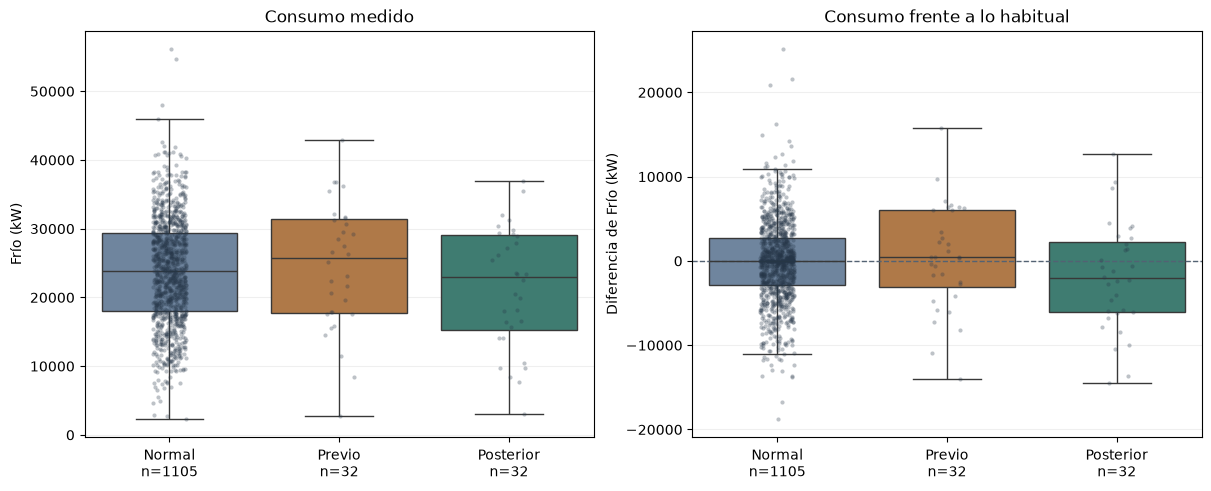

In [18]:
col_frio_jornada = 'Frio (Kw) (Consolidado EE)'
fechas_jornada = pd.to_datetime(df_final['DIA']).dt.normalize()
calendario_jornada = pd.date_range(fechas_jornada.min(), fechas_jornada.max(), freq='D')
mediciones_jornada = df_final.columns.difference(['DIA', 'HORA'])
hay_medicion = df_final[mediciones_jornada].notna().any(axis=1).groupby(fechas_jornada).any()
hay_medicion = hay_medicion.reindex(calendario_jornada, fill_value=False)

dias_huecos = hay_medicion.index[~hay_medicion]
un_dia = pd.Timedelta(days=1)
dias_previos = (dias_huecos - un_dia).intersection(hay_medicion.index[hay_medicion])
dias_posteriores = (dias_huecos + un_dia).intersection(hay_medicion.index[hay_medicion])
dias_entre_huecos = dias_previos.intersection(dias_posteriores)

es_cierre_jornada = df_final['HORA'].map(normalizar_hora).eq('23:59:00')
frio_jornada = df_final.loc[es_cierre_jornada, col_frio_jornada]
frio_jornada = pd.to_numeric(frio_jornada, errors='coerce')
frio_jornada.index = fechas_jornada.loc[es_cierre_jornada]
frio_jornada = frio_jornada[frio_jornada.index.notna() & np.isfinite(frio_jornada)]
assert frio_jornada.index.is_unique, 'Hay más de un cierre de Frío por fecha.'

comparacion_jornada = frio_jornada.drop(index=dias_entre_huecos, errors='ignore').to_frame('Frío medido')
comparacion_jornada['Grupo'] = 'Normal'
comparacion_jornada.loc[comparacion_jornada.index.isin(dias_previos), 'Grupo'] = 'Previo'
comparacion_jornada.loc[comparacion_jornada.index.isin(dias_posteriores), 'Grupo'] = 'Posterior'
comparacion_jornada['Mes'] = comparacion_jornada.index.month
comparacion_jornada['Día de semana'] = comparacion_jornada.index.day_of_week

claves_jornada = ['Mes', 'Día de semana']
referencias_jornada = (
    comparacion_jornada.loc[comparacion_jornada['Grupo'].eq('Normal')]
    .groupby(claves_jornada)['Frío medido']
    .agg(Referencia='median', Dias_normales='count')
)
comparacion_jornada = comparacion_jornada.join(referencias_jornada, on=claves_jornada)
comparacion_jornada['Diferencia'] = (
    comparacion_jornada['Frío medido'] - comparacion_jornada['Referencia']
).where(comparacion_jornada['Dias_normales'].ge(3))

print(f'Días 100 % huecos: {len(dias_huecos)}')
print(f'Días entre dos huecos: {len(dias_entre_huecos)}')
print(f'Días del gráfico izquierdo sin referencia suficiente: {comparacion_jornada["Diferencia"].isna().sum()}')

orden_jornada = ['Normal', 'Previo', 'Posterior']
colores_jornada = {'Normal': '#6785a6', 'Previo': '#c07837', 'Posterior': '#358677'}
fig_jornada, ejes_jornada = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained')
for eje, columna, titulo, unidad in zip(
    ejes_jornada,
    ['Frío medido', 'Diferencia'],
    ['Consumo medido', 'Consumo frente a lo habitual'],
    ['Frío (kW)', 'Diferencia de Frío (kW)'],
):
    puntos = comparacion_jornada.dropna(subset=[columna])
    if not puntos.empty:
        sns.boxplot(data=puntos, x='Grupo', y=columna, order=orden_jornada,
                    hue='Grupo', palette=colores_jornada, legend=False,
                    showfliers=False, ax=eje)
        sns.stripplot(data=puntos, x='Grupo', y=columna, order=orden_jornada,
                      color='#263648', alpha=.30, size=3, ax=eje)
    conteos = puntos['Grupo'].value_counts()
    eje.set_xticks(range(len(orden_jornada)), [f'{grupo}\nn={conteos.get(grupo, 0)}' for grupo in orden_jornada])
    eje.set_title(titulo)
    eje.set_xlabel('')
    eje.set_ylabel(unidad)
    eje.grid(axis='y', alpha=.2)
ejes_jornada[1].axhline(0, color='#536273', linewidth=1, linestyle='--')
plt.show()

### Matriz de nulidad de las lecturas registradas

Cada fila es una lectura existente y cada columna es una variable. La matriz permite ver huecos por bloque y columnas vacías. El calendario de arriba también cuenta fechas y horas que no tienen una fila en la tabla.

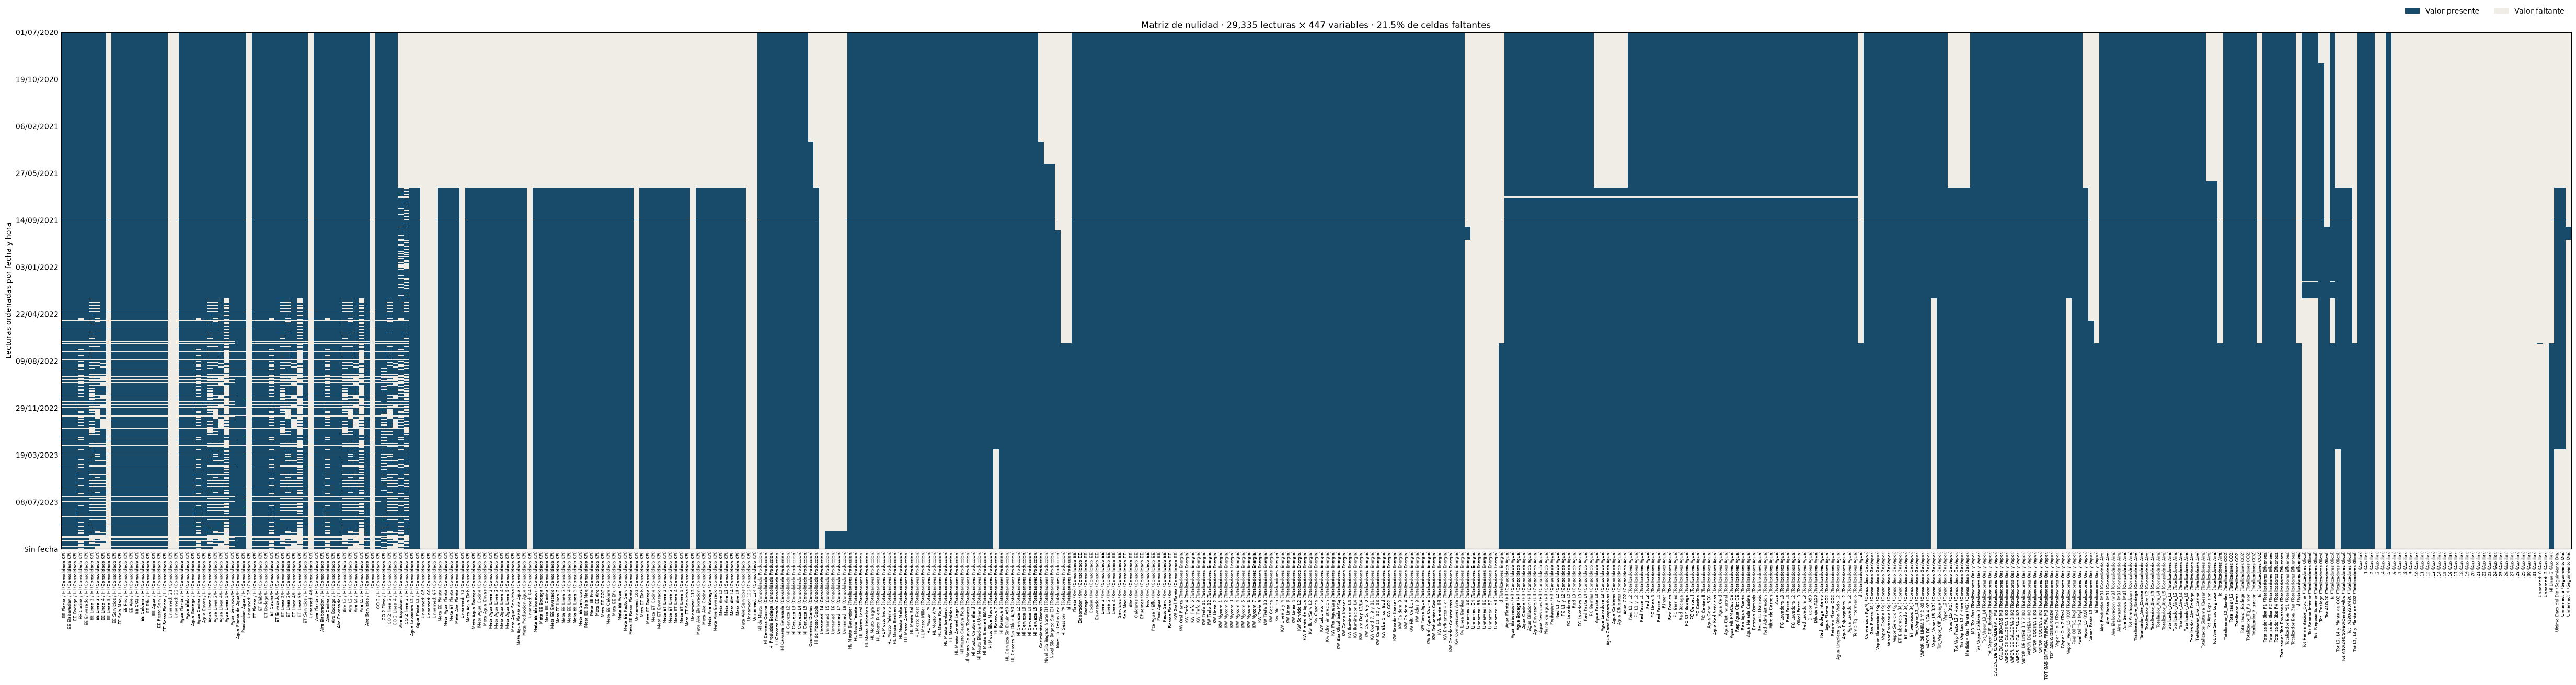

In [19]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Las claves identifican cada lectura; la matriz muestra únicamente las mediciones.
lecturas_matriz = df_final.sort_values(['DIA', 'HORA'])
tabla_nulidad = lecturas_matriz.drop(columns=['DIA', 'HORA'])
nulos_matriz = tabla_nulidad.isna().to_numpy()
filas, columnas = nulos_matriz.shape
fig, ax = plt.subplots(figsize=(max(14, columnas * .11), 13), layout='constrained')
colores_nulidad = ['#184b69', '#f0ede7']
ax.imshow(nulos_matriz, aspect='auto', interpolation='nearest', cmap=ListedColormap(colores_nulidad),
          vmin=0, vmax=1)
ax.set_xticks(np.arange(columnas), tabla_nulidad.columns, rotation=90, fontsize=6)
fechas_matriz = lecturas_matriz['DIA'].reset_index(drop=True)
marcas = np.linspace(0, filas - 1, min(12, filas), dtype=int)
ax.set_yticks(marcas, fechas_matriz.iloc[marcas].dt.strftime('%d/%m/%Y').fillna('Sin fecha'))
ax.tick_params(length=0)
ax.set_ylabel('Lecturas ordenadas por fecha y hora')
ax.set_title(f'Matriz de nulidad · {filas:,} lecturas × {columnas:,} variables · {nulos_matriz.mean():.1%} de celdas faltantes')
ax.legend(handles=[Patch(facecolor=colores_nulidad[0], label='Valor presente'),
                   Patch(facecolor=colores_nulidad[1], label='Valor faltante')],
          loc='upper right', bbox_to_anchor=(1, 1.06), ncol=2, frameon=False)
plt.show()

Ver rango de valores

In [20]:
columnas_numericas = [col for col in df_final.columns if col not in ['DIA', 'HORA']]
print("Rango de valores por columna:")
for col in columnas_numericas:
    minimo = df_final[col].min()
    maximo = df_final[col].max()
    print(f"- {col}: {minimo}  --->  {maximo}")

Rango de valores por columna:
- EE Planta / Hl (Consolidado KPI): -433.597186828919  --->  29886.6675796178
- EE Elaboracion / Hl (Consolidado KPI): -37.4285714285714  --->  624.0
- EE Bodega / Hl (Consolidado KPI): -449.738823106567  --->  748.0
- EE Cocina / Hl (Consolidado KPI): 0.0  --->  385.685080988917
- EE Envasado / Hl (Consolidado KPI): 0.0  --->  13148244844710.4
- EE Linea 2 / Hl (Consolidado KPI): -0.4425  --->  271.06
- EE Linea 3 / Hl (Consolidado KPI): 0.0  --->  873.0
- EE Linea 4 / Hl (Consolidado KPI): 0.0  --->  1875.0
- EE Linea 5 / Hl (Consolidado KPI): nan  --->  nan
- EE Servicios / Hl (Consolidado KPI): -213.523255813954  --->  3777.25
- EE Sala Maq / Hl (Consolidado KPI): -72.6675628961014  --->  6164417652379.456
- EE Frio / Hl (Consolidado KPI): 0.0  --->  6164417652379.278
- EE Aire / Hl (Consolidado KPI): -74.7167274822355  --->  681.3333333333334
- EE CO2 / Hl (Consolidado KPI): 0.0  --->  262.8333333333333
- EE Caldera / Hl (Consolidado KPI): 0.0  --->  

### Valores imposibles y outliers en los cierres diarios

Los totalizadores acumulan consumo desde la medianoche, así que un cierre diario no puede ser negativo. Los valores del orden de 10¹² a 10¹⁶ del rango anterior son desbordes del contador, no consumos reales. Separamos dos casos:

- **Valores imposibles:** infinitos, negativos en columnas de consumo acumulado, mayores a 100 veces la mediana de los valores positivos de la columna y, para `Frio (Kw)`, cualquier valor de 1.000.000 kW o más (escala de error descripta en la consigna). Los reemplazamos por faltantes; el preprocesamiento decide cómo imputarlos usando solo estadísticos de train.
- **Outliers estadísticos (IQR):** valores poco frecuentes pero posibles, como días de parada o de alta producción. Solo los contamos, porque pueden ser días reales que el modelo tiene que aprender.

Los niveles (`Nivel …`) y temperaturas (`Temp …`) no son acumulados y quedan fuera de la regla de negativos.

### Selección del cierre diario

El cierre de las `23:59:00` concentra las mediciones de ese minuto, alineadas en el punto 5. Verificamos que quede una fila por fecha antes de usarla en el análisis diario.


In [21]:
df = df_final.loc[df_final['HORA'].eq('23:59:00') & df_final['DIA'].notna()].copy()
assert df['DIA'].is_unique, 'Hay más de un cierre para alguna fecha.'


### Cierre a las 23:59 frente a las 23:00

La consigna permite cerrar el día a las 23:00 o a las 23:59. Comparamos ambos para `Frio (Kw)` en los días que tienen las dos lecturas válidas. Si los totalizadores se reinician a medianoche, la lectura de las 23:59 contiene el consumo del día completo y la de las 23:00 deja afuera la última hora.

In [22]:
col_frio = 'Frio (Kw) (Consolidado EE)'
lecturas_finales = df_final.loc[df_final['HORA'].isin(['23:00:00', '23:59:00']), ['DIA', 'HORA', col_frio]]
comparacion_cierre = lecturas_finales.pivot_table(index='DIA', columns='HORA', values=col_frio, aggfunc='first')
if {'23:00:00', '23:59:00'} <= set(comparacion_cierre.columns):
    comparacion_cierre = comparacion_cierre.where(comparacion_cierre.ge(0) & comparacion_cierre.lt(1_000_000)).dropna()
    ultima_hora = comparacion_cierre['23:59:00'] - comparacion_cierre['23:00:00']
    porcentaje_ultima_hora = ultima_hora / comparacion_cierre['23:59:00'].where(comparacion_cierre['23:59:00'].gt(0)) * 100
    print(f'Días con ambas lecturas válidas: {len(comparacion_cierre)}')
    print(f'Consumo de Frío entre 23:00 y 23:59 (mediana): {ultima_hora.median():,.0f} kW '
          f'= {porcentaje_ultima_hora.median():.1f} % del total diario')
    print(f'Días en que la lectura de 23:59 es menor que la de 23:00: {int(ultima_hora.lt(0).sum())}')
else:
    print('No hay lecturas de 23:00 y 23:59 para comparar.')

Días con ambas lecturas válidas: 1153
Consumo de Frío entre 23:00 y 23:59 (mediana): 949 kW = 4.0 % del total diario
Días en que la lectura de 23:59 es menor que la de 23:00: 1


Usamos el cierre de las **23:59** porque es la última lectura antes del reinicio y contiene el consumo del día completo. Con las 23:00 perderíamos la última hora (el porcentaje medido arriba, cercano a 1/24 del día), y ese error se trasladaría tanto al target como a los lags. Los días en que la lectura de 23:59 es menor que la de 23:00 indican un reinicio anticipado o un error de registro y se revisan en la sección de reinicios.

### Columnas que entran al análisis

Partimos de los cierres diarios y aplicamos tres filtros sobre las columnas:

1. **No son mediciones:** columnas sin nombre, identificadores (`Id`), metas de gestión (`Meta …`), hojas de control (`Auxiliar`, `Seguimiento Dia`) y KPI por hectolitro, que son cocientes de otras columnas.
2. **Sin información suficiente:** columnas con datos en menos de la mitad de los días o constantes.
3. **Duplicadas:** columnas idénticas a otra, por ejemplo la misma variable en la hoja `Consolidado` y en `Totalizadores`. Conservamos la primera.

`df_cierres_crudos` guarda los cierres antes de la limpieza. Desde acá, `df` tiene los valores imposibles como faltantes y `columnas_analisis` lista las columnas que usamos en correlaciones y selección.

In [23]:
df_cierres_crudos = df.copy()
col_frio = 'Frio (Kw) (Consolidado EE)'
columnas_medicion = [col for col in df.columns if col not in ('DIA', 'HORA')]


def motivo_exclusion(columna):
    nombre = columna.strip()
    if nombre.endswith(('(Auxiliar)', '(Seguimiento Dia)')):
        return 'Hoja auxiliar o de control'
    if nombre.startswith('Unnamed') or re.fullmatch(r'(\.\d+\s*)?\([^()]*\)', nombre):
        return 'Columna sin nombre'
    if nombre.startswith('Id ('):
        return 'Identificador de registro'
    if nombre.startswith('Meta '):
        return 'Meta de gestión'
    if nombre.endswith('(Consolidado KPI)'):
        return 'KPI derivado (por Hl)'
    return None


def mascara_imposibles(serie, columna):
    invalida = np.isinf(serie)
    if not re.search(r'Nivel|Temp', columna, flags=re.IGNORECASE):
        invalida |= serie.lt(0)
    positivos = serie[serie.gt(0) & np.isfinite(serie)]
    if len(positivos) >= 10:
        invalida |= serie.gt(100 * positivos.median())
    if columna == col_frio:
        invalida |= serie.ge(1_000_000)
    return invalida


# 1. Valores imposibles -> faltantes
conteo_imposibles = {}
for columna in columnas_medicion:
    invalida = mascara_imposibles(df[columna], columna)
    if invalida.any():
        conteo_imposibles[columna] = int(invalida.sum())
        df[columna] = df[columna].mask(invalida)

conteo_imposibles = pd.Series(conteo_imposibles, dtype=int).sort_values(ascending=False)
print(f'Valores imposibles reemplazados por faltantes: {conteo_imposibles.sum()} en {len(conteo_imposibles)} columnas')
print(f'Cierres de Frío imposibles: {conteo_imposibles.get(col_frio, 0)} de {df_cierres_crudos[col_frio].notna().sum()}')
display(conteo_imposibles.head(15).to_frame('Valores imposibles'))

dias_frio_cero = df.loc[df[col_frio].eq(0), 'DIA']
print(f'Días con cierre de Frío igual a 0: {len(dias_frio_cero)}')
if not dias_frio_cero.empty:
    print('  ', ', '.join(dias_frio_cero.dt.strftime('%Y-%m-%d')))

# 2. Columnas que no son mediciones, sin datos suficientes o constantes
motivos_exclusion = {col: motivo_exclusion(col) for col in columnas_medicion}
motivos_exclusion = {col: motivo for col, motivo in motivos_exclusion.items() if motivo}
candidatas = [col for col in columnas_medicion if col not in motivos_exclusion]
cobertura = df[candidatas].notna().mean()
for col in candidatas:
    if cobertura[col] < 0.5:
        motivos_exclusion[col] = 'Datos en menos del 50 % de los días'
    elif df[col].nunique(dropna=True) <= 1:
        motivos_exclusion[col] = 'Constante'

# 3. Columnas idénticas a otra
primera_con_valores = {}
for col in candidatas:
    if col in motivos_exclusion:
        continue
    firma = tuple(df[col].round(6).fillna(np.inf))
    if firma in primera_con_valores:
        motivos_exclusion[col] = f'Duplicada de: {primera_con_valores[firma]}'
    else:
        primera_con_valores[firma] = col

columnas_analisis = [col for col in columnas_medicion if col not in motivos_exclusion]
resumen_exclusion = (pd.Series(motivos_exclusion)
                     .str.replace(r'^Duplicada de: .*', 'Duplicada de otra columna', regex=True)
                     .value_counts())
print(f'\nColumnas de medición: {len(columnas_medicion)} | columnas para el análisis: {len(columnas_analisis)}')
display(resumen_exclusion.to_frame('Columnas excluidas'))

Valores imposibles reemplazados por faltantes: 758 en 84 columnas
Cierres de Frío imposibles: 0 de 1169


,Valores imposibles
Tot Reposo Superior (Totalizadores Glicol),185
TOT AGUA DESAIREADA (Totalizadores Gas y Vapor),156
Resto Serv (Kw) (Consolidado EE),40
EE Resto Serv / Hl (Consolidado KPI),38
Aire Servicios / Hl (Consolidado KPI),23
Aire Servicios (M3) (Consolidado Aire),23
Restos Planta (Kw) (Consolidado EE),19
FC Lavadora L2 (Consolidado Agua),17
FC Lavadora L2 (Totalizadores Agua),17
EE Resto Planta / Hl (Consolidado KPI),17


Días con cierre de Frío igual a 0: 0

Columnas de medición: 447 | columnas para el análisis: 216


,Columnas excluidas
KPI derivado (por Hl),59
Meta de gestión,51
Hoja auxiliar o de control,38
Duplicada de otra columna,27
Columna sin nombre,25
Constante,19
Identificador de registro,8
Datos en menos del 50 % de los días,4


In [24]:
def detectar_outliers_iqr(dataframe, columnas):
    resumen = {}
    for col in columnas:
        serie = dataframe[col].dropna()
        if serie.empty:
            continue
        q1, q3 = serie.quantile([0.25, 0.75])
        iqr = q3 - q1
        cantidad = int(((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).sum())
        if cantidad:
            resumen[col] = {'Outliers IQR': cantidad, '% de los días con dato': cantidad / len(serie) * 100}
    if not resumen:
        return pd.DataFrame(columns=['Outliers IQR', '% de los días con dato'])
    return pd.DataFrame(resumen).T.sort_values('Outliers IQR', ascending=False)


# Se calcula después de reemplazar los valores imposibles, para que los desbordes no definan los cuartiles.
outliers_iqr = detectar_outliers_iqr(df, columnas_analisis)
print(f'Columnas con al menos un outlier IQR: {len(outliers_iqr)} de {len(columnas_analisis)}')
display(outliers_iqr.head(15).round(1))
if col_frio in outliers_iqr.index:
    print(f"Frío: {int(outliers_iqr.loc[col_frio, 'Outliers IQR'])} cierres fuera de 1,5·IQR. "
          'No se eliminan: son días posibles y el modelo tiene que poder predecirlos.')
else:
    print('Frío: sin outliers IQR después de quitar los valores imposibles.')

Columnas con al menos un outlier IQR: 154 de 216


,Outliers IQR,% de los días con dato
Rinser (Totalizadores Agua),291.0,24.9
Totalizador_L2_Barriles (Totalizadores CO2),277.0,23.7
Red Bodega (Totalizadores Agua),256.0,22.0
CAUDAL DE GAS CALDERA 1 M3 (Totalizadores Gas y Vapor),250.0,21.4
HL Mosto Heineken (Totalizadores Produccion),241.0,20.6
VAPOR DE LINEA 4 KG (Consolidado GasVapor),227.0,19.4
Totaliador_Aire_L4 (Consolidado Aire),225.0,19.2
Totalizador Bba Envasado (Totalizadores Efluentes),215.0,18.5
Retorno Planta CO2 (Totalizadores Agua),213.0,18.2
KW Filtr Carbon (Totalizadores Energia),191.0,16.4


Frío: 3 cierres fuera de 1,5·IQR. No se eliminan: son días posibles y el modelo tiene que poder predecirlos.


### Días con menos de 25 registros en la tabla unificada

El conteo considera las filas de todas las hojas cruzadas. La referencia es de 24 lecturas horarias más el cierre. Para saber si una jornada incompleta puede aportar la etiqueta del día anterior, revisar aparte si tiene un cierre de `Frio (Kw)` observado y válido.


In [25]:
AMARILLO = "\033[38;2;165;132;64m"
VERDE = "\033[32m"
NEGRITA = "\033[1m"
RESET = "\033[0m"

conteo_por_dia = df_final.groupby('DIA').size()
dias_incompletos = conteo_por_dia[conteo_por_dia < 25]

es_cierre = df_final['HORA'].eq('23:59:00')
fechas_con_cierre = set(df_final.loc[es_cierre, 'DIA'])

print(f"{NEGRITA}Días con menos de 25 registros:{RESET}")
if dias_incompletos.empty:
    print(f"{VERDE}No hay días con menos de 25 registros.{RESET}")
else:
    for fecha, cantidad in dias_incompletos.items():
        nota = ""
        if fecha in fechas_con_cierre:
            nota = f" {VERDE}(Pero tiene el cierre de las 23:59){RESET}"
        print(f" - {fecha:%Y-%m-%d}: {AMARILLO}{cantidad} registros{RESET}{nota}")


Días con menos de 25 registros:
 - 2020-08-05: 24 registros (Pero tiene el cierre de las 23:59)
 - 2020-10-15: 24 registros (Pero tiene el cierre de las 23:59)
 - 2021-07-13: 23 registros
 - 2021-10-09: 24 registros (Pero tiene el cierre de las 23:59)
 - 2021-11-01: 23 registros (Pero tiene el cierre de las 23:59)
 - 2022-03-02: 24 registros
 - 2022-03-05: 24 registros (Pero tiene el cierre de las 23:59)
 - 2023-01-17: 16 registros (Pero tiene el cierre de las 23:59)
 - 2023-04-13: 20 registros
 - 2023-04-19: 17 registros
 - 2023-07-01: 23 registros (Pero tiene el cierre de las 23:59)
 - 2023-10-26: 8 registros


### Totalizadores que no se reiniciaron a medianoche

Un totalizador que se reinicia a las 00:00 marca cerca de cero en la primera lectura del día. Consideramos que **no se reinició** cuando la lectura de las 00:00 del día `D` es al menos la mitad del cierre del día `D-1`: el contador siguió sumando sobre el día anterior. Revisamos solo las columnas de `columnas_analisis` que son consumos acumulados (sin niveles ni temperaturas), así el resultado no se llena de identificadores, metas o columnas auxiliares.

In [26]:
columnas_totalizadores = [col for col in columnas_analisis if not re.search(r'Nivel|Temp', col, flags=re.IGNORECASE)]
lecturas_00 = (df_final.loc[df_final['HORA'].eq('00:00:00') & df_final['DIA'].notna(), ['DIA', *columnas_totalizadores]]
               .drop_duplicates('DIA').set_index('DIA'))
for columna in columnas_totalizadores:
    lecturas_00[columna] = lecturas_00[columna].mask(mascara_imposibles(lecturas_00[columna], columna))

cierre_dia_anterior = df.set_index('DIA')[columnas_totalizadores]
cierre_dia_anterior.index = cierre_dia_anterior.index + pd.Timedelta(days=1)
fechas_comunes = lecturas_00.index.intersection(cierre_dia_anterior.index)
lectura_00, cierre_previo = lecturas_00.loc[fechas_comunes], cierre_dia_anterior.loc[fechas_comunes]
sin_reinicio = lectura_00.ge(0.5 * cierre_previo) & cierre_previo.gt(0)

dias_sin_reinicio = sin_reinicio.sum().sort_values(ascending=False)
dias_sin_reinicio = dias_sin_reinicio[dias_sin_reinicio.gt(0)]
print(f'Días comparados: {len(fechas_comunes)}')
print(f'Columnas con al menos un día sin reinicio: {len(dias_sin_reinicio)} de {len(columnas_totalizadores)}')
display(dias_sin_reinicio.head(15).to_frame('Días sin reinicio'))

fechas_frio_sin_reinicio = sin_reinicio.index[sin_reinicio[col_frio].to_numpy()] if col_frio in sin_reinicio else pd.DatetimeIndex([])
print(f'Días en que Frío no se reinició: {len(fechas_frio_sin_reinicio)}')
if len(fechas_frio_sin_reinicio):
    print('  ', ', '.join(fechas_frio_sin_reinicio.strftime('%Y-%m-%d')))

Días comparados: 1121
Columnas con al menos un día sin reinicio: 67 de 212


,Días sin reinicio
Cocimientos Diarios (Consolidado Produccion),49
Tot Vap Lav L3 / Hora (Consolidado GasVapor),10
Bodega (Kw) (Consolidado EE),2
Kw Admininistracion (Totalizadores Energia),2
KW Trafo 10 (Totalizadores Energia),2
Elaboracion (Kw) (Consolidado EE),2
Linea 4 (Kw) (Consolidado EE),1
Pta Agua / Eflu (Kw) (Consolidado EE),1
Restos Planta (Kw) (Consolidado EE),1
Calderas (Kw) (Consolidado EE),1


Días en que Frío no se reinició: 1
   2020-07-11


En un día sin reinicio, el cierre puede incluir consumo del día anterior y sobrestimar el total. Las fechas de Frío quedan en `fechas_frio_sin_reinicio` para que el preprocesamiento las trate como faltantes o las corrija restando el valor inicial. En las demás columnas el efecto se limita a esa variable y se resuelve con la misma regla.

## Análisis temporal

### Variable objetivo: consumo de Frío del día siguiente

Para cada fecha `D`, se busca el cierre observado de `Frio (Kw)` en `Consolidado EE` para la fecha `D + 1`. Si falta esa fecha o su valor de Frío, la etiqueta queda vacía. Por ejemplo, si falta el cierre del 28 de febrero, la fila del 27 queda sin etiqueta observable.


In [27]:
df = df.sort_values('DIA').reset_index(drop=True).copy()
col_frio = 'Frio (Kw) (Consolidado EE)'
frio_por_fecha = df.set_index('DIA')[col_frio]
frio_por_fecha = frio_por_fecha.where(np.isfinite(frio_por_fecha))
df['Target_Frio_Manana'] = (df['DIA'] + pd.Timedelta(days=1)).map(frio_por_fecha)


### Autocorrelación del Frío por calendario

Correlacionamos el Frío de cada día con el de `k` días antes, desplazando por fecha y no por fila: un día faltante queda como faltante y no corre la serie. El rezago 1 equivale a la correlación entre el Frío de hoy y el target. Un pico en el rezago 7 indica un ciclo semanal.

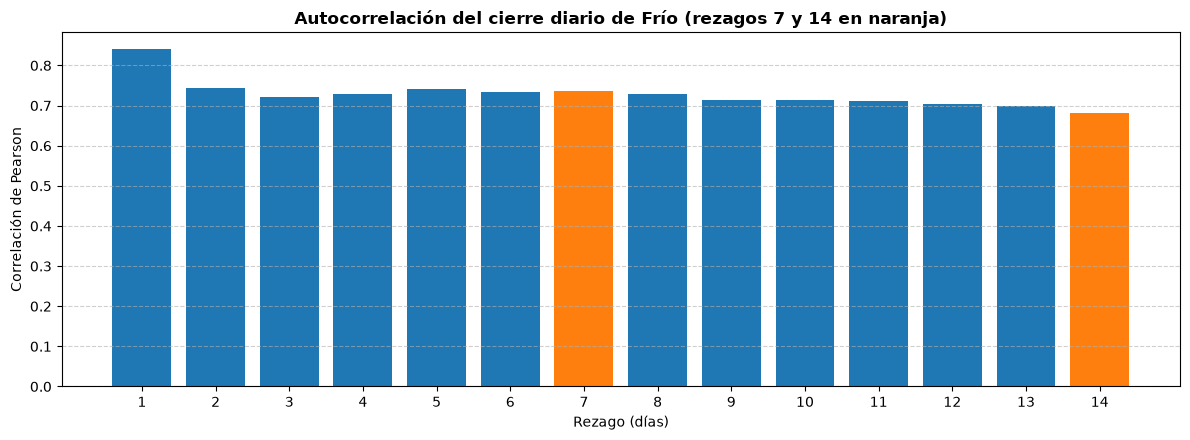

1     0.840
2     0.743
3     0.722
4     0.729
5     0.741
6     0.734
7     0.736
8     0.728
9     0.715
10    0.715
11    0.710
12    0.704
13    0.699
14    0.681


In [28]:
serie_frio = df.set_index('DIA')[col_frio].asfreq('D')
autocorrelacion = pd.Series(
    {rezago: serie_frio.corr(serie_frio.shift(rezago)) for rezago in range(1, 15)}, name='Correlación'
)

fig, ax = plt.subplots(figsize=(12, 4.5))
colores = ['#ff7f0e' if rezago % 7 == 0 else '#1f77b4' for rezago in autocorrelacion.index]
ax.bar(autocorrelacion.index, autocorrelacion.values, color=colores)
ax.set_xticks(autocorrelacion.index)
ax.set_xlabel('Rezago (días)')
ax.set_ylabel('Correlación de Pearson')
ax.set_title('Autocorrelación del cierre diario de Frío (rezagos 7 y 14 en naranja)', fontweight='bold')
ax.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()
print(autocorrelacion.round(3).to_string())

### Serie temporal, estacionalidad y tendencia

Con los valores imposibles ya removidos, graficamos el cierre diario de Frío y su distribución por mes y por año.

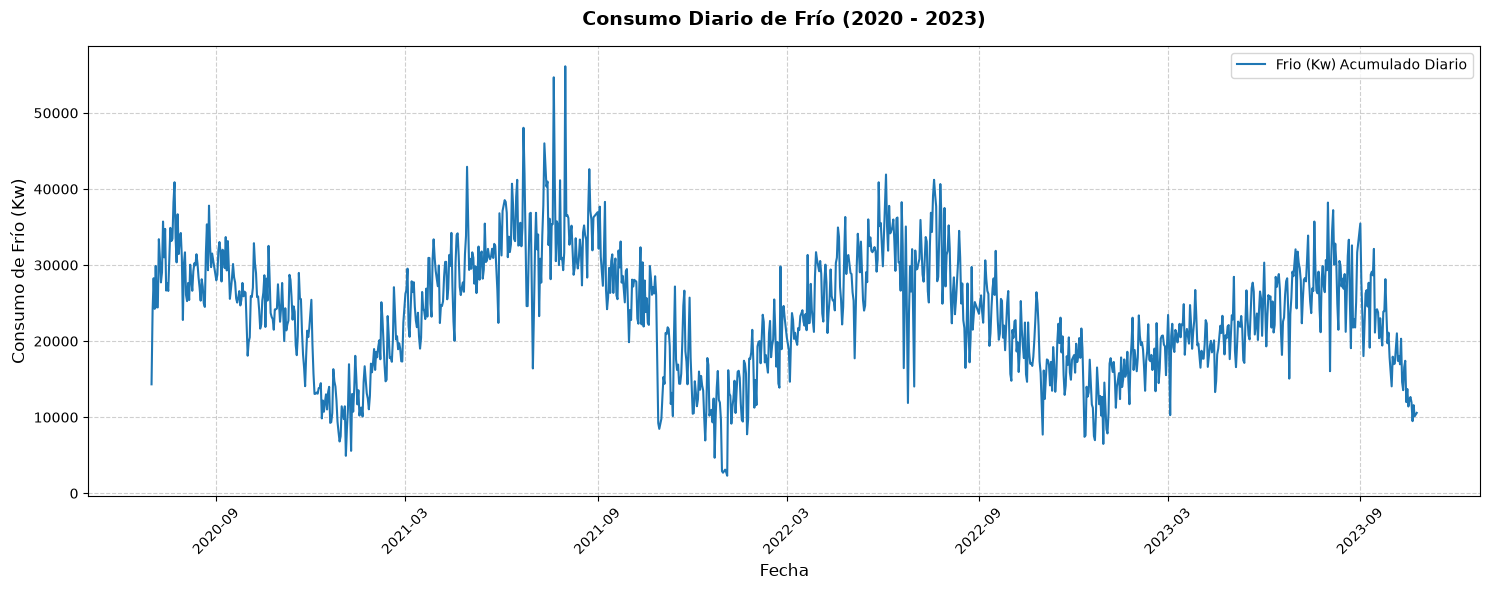

In [29]:


plt.figure(figsize=(15, 6))

# Generar el gráfico de líneas
plt.plot(df['DIA'], df['Frio (Kw) (Consolidado EE)'], 
         color='#1f77b4', linewidth=1.5, label='Frio (Kw) Acumulado Diario')

# Configuración de etiquetas y título
plt.title('Consumo Diario de Frío (2020 - 2023)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Consumo de Frío (Kw)', fontsize=12)

# --- NUEVO CÓDIGO PARA EL EJE X ---
ax = plt.gca() # Obtener los ejes actuales

# Mostrar las etiquetas cada 6 meses
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))

# Darle formato a la fecha (por ejemplo: '2020-01' para Año-Mes. Puedes usar '%Y-%m-%d' para día también)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

# Rotar las fechas 45 grados para que no se superpongan
plt.xticks(rotation=45)
# ----------------------------------

# Formato visual
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

# Ajustar los márgenes automáticamente para que no se corten las etiquetas
plt.tight_layout()

# Mostrar el gráfico en pantalla
plt.show()

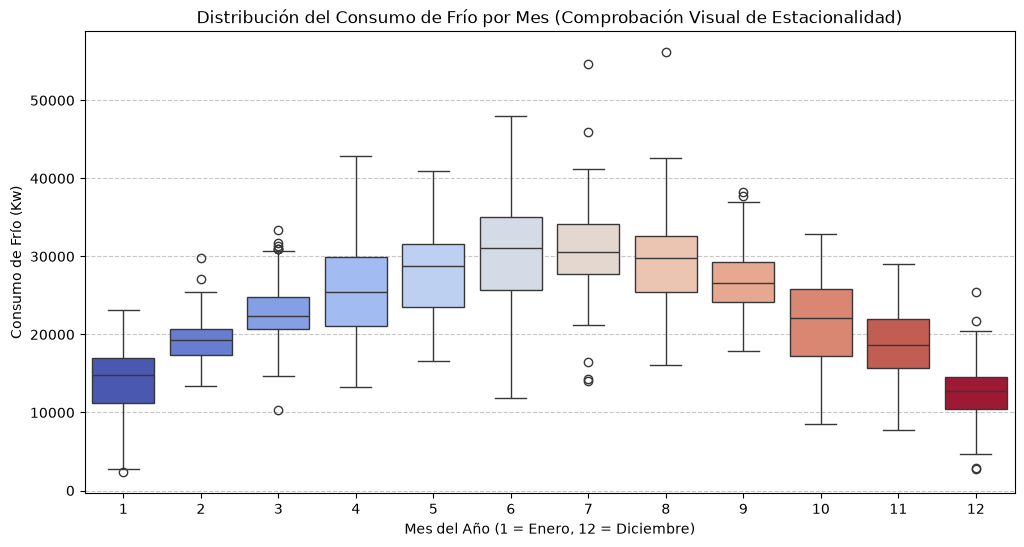

In [30]:
df = df.copy()

# Convertir la fecha y crear las columnas
df['DIA'] = pd.to_datetime(df['DIA'])
df['Mes'] = df['DIA'].dt.month
df['Año'] = df['DIA'].dt.year

plt.figure(figsize=(12, 6))
sns.boxplot(
    x='Mes', 
    y='Frio (Kw) (Consolidado EE)', 
    data=df, 
    hue='Mes', 
    palette='coolwarm', 
    legend=False
)

plt.title('Distribución del Consumo de Frío por Mes (Comprobación Visual de Estacionalidad)')
plt.xlabel('Mes del Año (1 = Enero, 12 = Diciembre)')
plt.ylabel('Consumo de Frío (Kw)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

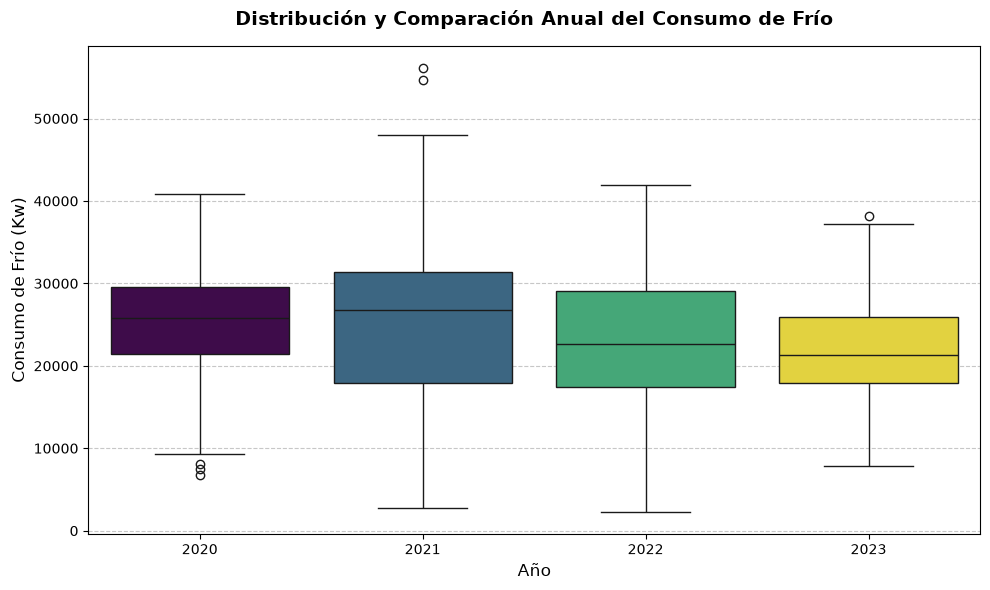

In [31]:
plt.figure(figsize=(10, 6))

# Generar el boxplot por Año
sns.boxplot(
    x='Año', 
    y='Frio (Kw) (Consolidado EE)', 
    data=df, 
    hue='Año', 
    palette='viridis', # Paleta de colores distinta para que se vea bien
    legend=False
)

# Configuración de etiquetas y título
plt.title('Distribución y Comparación Anual del Consumo de Frío', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Año', fontsize=12)
plt.ylabel('Consumo de Frío (Kw)', fontsize=12)

# Formato visual
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Mostrar el gráfico
plt.show()

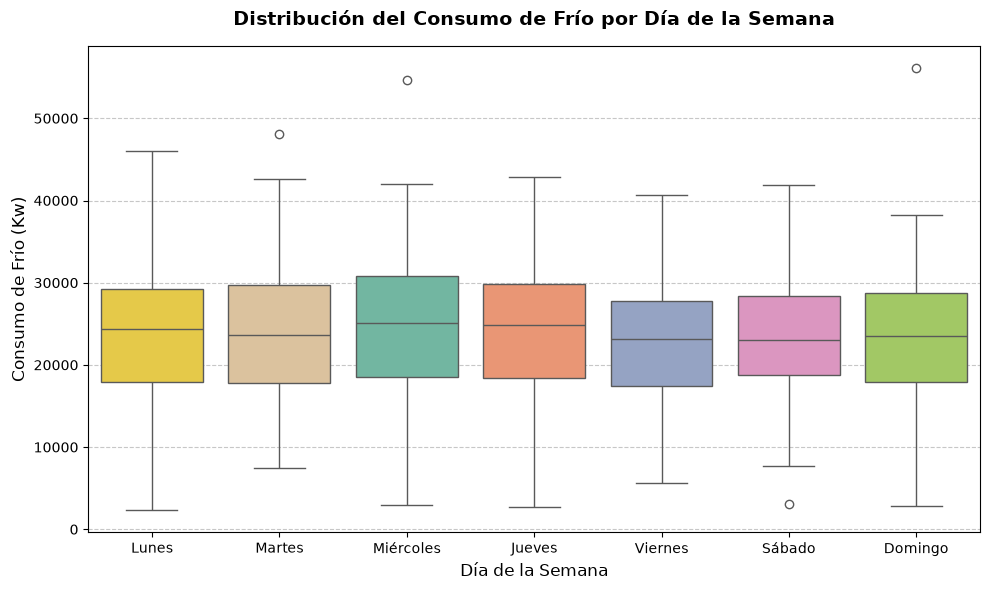

In [32]:
df['Dia_Num'] = df['DIA'].dt.day_of_week

# Mapeamos los números a los nombres de los días
nombres_dias = {0: 'Lunes', 1: 'Martes', 2: 'Miércoles', 3: 'Jueves', 4: 'Viernes', 5: 'Sábado', 6: 'Domingo'}
df['Dia_Semana'] = df['Dia_Num'].map(nombres_dias)

# Definimos el orden lógico para que el gráfico empiece el Lunes y termine el Domingo
orden_dias = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']

plt.figure(figsize=(10, 6))

sns.boxplot(
    x='Dia_Semana', 
    y='Frio (Kw) (Consolidado EE)', 
    data=df, 
    order=orden_dias, # Obligamos a que respete el orden de Lunes a Domingo
    hue='Dia_Semana',
    palette='Set2', 
    legend=False
)

plt.title('Distribución del Consumo de Frío por Día de la Semana', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Día de la Semana', fontsize=12)
plt.ylabel('Consumo de Frío (Kw)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Consumo de Frío por día de la semana ajustado por mes

El consumo típico de julio puede ser distinto al de enero. Para descontar esa diferencia, calculamos la **mediana del Frío de cada mes del año**, juntando todos los años disponibles y todos los días de la semana. Después, a cada lectura le restamos la mediana de su mes.

Por ejemplo, si un lunes de julio consumió **32.000** y la mediana de julio fue **30.000**, ese lunes aparece como **+2.000**. Hacemos lo mismo con cada lectura y recién ahí armamos las cajas de lunes a domingo.

El **cero** marca el consumo típico del mes. Si la caja de los lunes queda más arriba que las demás, hay una pista de que los lunes suelen consumir más de lo habitual para la época. Este ajuste descuenta el nivel típico de cada mes. La temperatura de cada día todavía puede influir.

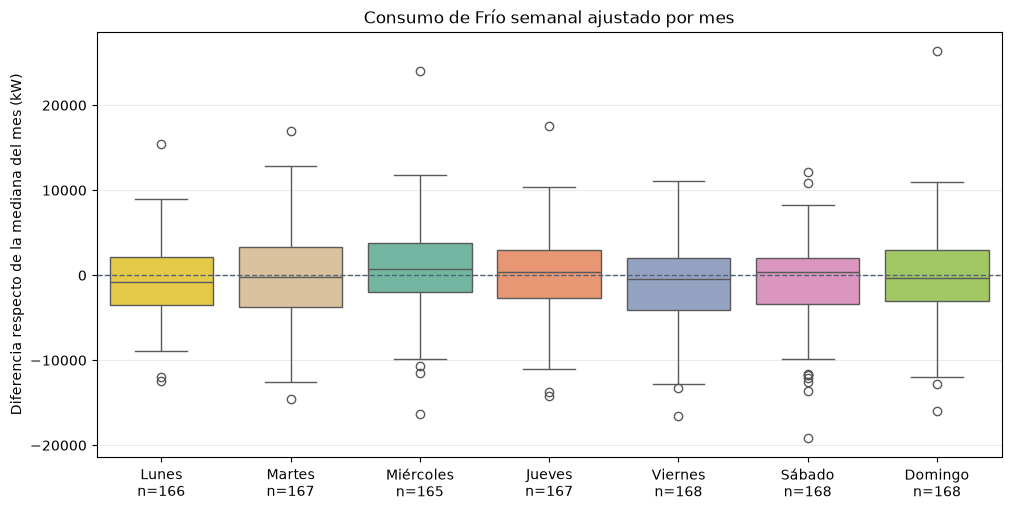

In [33]:
col_frio_ajuste = 'Frio (Kw) (Consolidado EE)'
frio_ajustado = df.loc[
    df['DIA'].notna() & np.isfinite(df[col_frio_ajuste]),
    ['DIA', 'Dia_Semana', col_frio_ajuste],
].copy()
frio_tipico_mes = frio_ajustado.groupby(frio_ajustado['DIA'].dt.month)[col_frio_ajuste].transform('median')
frio_ajustado['Diferencia'] = frio_ajustado[col_frio_ajuste] - frio_tipico_mes

fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
if not frio_ajustado.empty:
    sns.boxplot(data=frio_ajustado, x='Dia_Semana', y='Diferencia',
                order=orden_dias, hue='Dia_Semana', palette='Set2', legend=False, ax=ax)
conteos_ajuste = frio_ajustado['Dia_Semana'].value_counts()
ax.set_xticks(range(len(orden_dias)), [f'{dia}\nn={conteos_ajuste.get(dia, 0)}' for dia in orden_dias])
ax.axhline(0, color='#536273', linewidth=1, linestyle='--')
ax.set(title='Consumo de Frío semanal ajustado por mes', xlabel='',
       ylabel='Diferencia respecto de la mediana del mes (kW)')
ax.grid(axis='y', alpha=.25)
ax.set_axisbelow(True)
plt.show()

### Efecto del día de la semana medido

Los dos boxplots anteriores muestran el patrón, con y sin el ajuste por mes; acá lo cuantificamos de dos maneras:

- **Efecto bruto:** test de Kruskal-Wallis entre los siete días (no supone normalidad) y η², la proporción de la variancia del Frío explicada por el día de la semana.
- **Efecto neto:** para cada día, la diferencia entre su Frío y el promedio de su propia semana ISO, usando solo semanas completas. Así descontamos la estacionalidad y la tendencia, que cambian de una semana a otra, y obtenemos cuántos kW más o menos consume cada día respecto de su semana.

Como el target es el Frío de `D+1`, la variable útil para el modelo es el día de la semana de mañana, que se conoce de antemano y no genera fuga.

In [34]:
frio_semana = df.loc[df[col_frio].notna(), ['DIA', col_frio]].copy()
frio_semana['Dia_Semana'] = frio_semana['DIA'].dt.day_of_week.map(nombres_dias)

# Efecto bruto
grupos_dia = [grupo[col_frio].to_numpy() for _, grupo in frio_semana.groupby('Dia_Semana')]
estadistico_kw, p_kruskal = stats.kruskal(*grupos_dia)
media_global = frio_semana[col_frio].mean()
ss_entre = sum(len(grupo) * (grupo.mean() - media_global) ** 2 for grupo in grupos_dia)
eta2_bruto = ss_entre / ((frio_semana[col_frio] - media_global) ** 2).sum()

# Efecto neto: desvío respecto del promedio de la propia semana
calendario_iso = frio_semana['DIA'].dt.isocalendar()
frio_semana['Semana'] = calendario_iso['year'].astype(str) + '-' + calendario_iso['week'].astype(str).str.zfill(2)
semanas_completas = frio_semana.loc[frio_semana.groupby('Semana')['DIA'].transform('size').eq(7)].copy()
semanas_completas['Desvio_semana'] = (semanas_completas[col_frio]
                                      - semanas_completas.groupby('Semana')[col_frio].transform('mean'))
media_desvio_por_dia = semanas_completas.groupby('Dia_Semana')['Desvio_semana'].transform('mean')
eta2_neto = (media_desvio_por_dia ** 2).sum() / (semanas_completas['Desvio_semana'] ** 2).sum()

efecto_dia = pd.DataFrame({
    'Días': frio_semana.groupby('Dia_Semana')[col_frio].size(),
    'Media (kW)': frio_semana.groupby('Dia_Semana')[col_frio].mean(),
    'Mediana (kW)': frio_semana.groupby('Dia_Semana')[col_frio].median(),
    'Diferencia con su semana (kW)': semanas_completas.groupby('Dia_Semana')['Desvio_semana'].mean(),
}).reindex(orden_dias)
efecto_dia['Diferencia con su semana (%)'] = (efecto_dia['Diferencia con su semana (kW)']
                                              / semanas_completas[col_frio].mean() * 100)
display(efecto_dia.round(1))

amplitud_semanal = (efecto_dia['Diferencia con su semana (kW)'].max()
                    - efecto_dia['Diferencia con su semana (kW)'].min())
es_fin_de_semana = frio_semana['DIA'].dt.day_of_week.ge(5)
_, p_fin_de_semana = stats.mannwhitneyu(frio_semana.loc[es_fin_de_semana, col_frio],
                                        frio_semana.loc[~es_fin_de_semana, col_frio])
print(f'Kruskal-Wallis entre días: H = {estadistico_kw:.1f}, p = {p_kruskal:.2e}')
print(f'η² bruto: {eta2_bruto:.3f} | η² dentro de cada semana: {eta2_neto:.3f} '
      f'(semanas completas: {semanas_completas["Semana"].nunique()})')
print(f'Diferencia entre el día de mayor y el de menor consumo, respecto de su semana: {amplitud_semanal:,.0f} kW')
print(f'Fin de semana contra días hábiles (Mann-Whitney): p = {p_fin_de_semana:.2e}')
if p_kruskal < 0.05:
    print(f'Conclusión: el día de la semana tiene un efecto significativo. La amplitud equivale al '
          f'{amplitud_semanal / 3000:.0%} del umbral de MAE de 3000 kW, así que lo incluimos como feature (día de D+1).')
else:
    print('Conclusión: no hay evidencia de efecto del día de la semana; no lo priorizamos como feature.')

,Días,Media (kW),Mediana (kW),Diferencia con su semana (kW),Diferencia con su semana (%)
Dia_Semana,,,,,
Lunes,166,23216.9,24399.0,-675.6,-2.8
Martes,167,23976.6,23655.0,205.4,0.9
Miércoles,165,24726.9,25048.0,1171.7,4.9
Jueves,167,24161.8,24875.0,554.2,2.3
Viernes,168,22942.8,23151.5,-846.1,-3.6
Sábado,168,23293.9,23064.0,-438.0,-1.8
Domingo,168,23466.2,23561.5,28.4,0.1


Kruskal-Wallis entre días: H = 5.9, p = 4.35e-01
η² bruto: 0.006 | η² dentro de cada semana: 0.039 (semanas completas: 135)
Diferencia entre el día de mayor y el de menor consumo, respecto de su semana: 2,018 kW
Fin de semana contra días hábiles (Mann-Whitney): p = 4.02e-01
Conclusión: no hay evidencia de efecto del día de la semana; no lo priorizamos como feature.


### Consumo de Frío por día de la semana y estación

Cada panel muestra un mes. Cada caja reúne las lecturas de cierre de Frío de un día de la semana dentro de ese mes, usando todos los años disponibles. Por ejemplo, la caja de los lunes de enero reúne los lunes de enero de todos los años. Debajo de cada día se indica cuántas lecturas válidas hay. Los tres paneles de la estación comparten escala vertical.

Para agrupar los meses usamos la convención meteorológica del hemisferio norte: primavera (marzo a mayo), verano (junio a agosto), otoño (septiembre a noviembre) e invierno (diciembre a febrero). Las flechas cambian la estación. El gráfico permite ver si el patrón semanal se sostiene en los tres meses o si cambia según el mes.


In [35]:
from io import BytesIO
import ipywidgets as widgets
from IPython.display import display

estaciones_frio = {
    'Primavera': [(3, 'Marzo'), (4, 'Abril'), (5, 'Mayo')],
    'Verano': [(6, 'Junio'), (7, 'Julio'), (8, 'Agosto')],
    'Otoño': [(9, 'Septiembre'), (10, 'Octubre'), (11, 'Noviembre')],
    'Invierno': [(12, 'Diciembre'), (1, 'Enero'), (2, 'Febrero')],
}
dias_semana_frio = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
columna_frio_estacion = 'Frio (Kw) (Consolidado EE)'
cierres_estacion = df.loc[df['DIA'].notna() & np.isfinite(df[columna_frio_estacion]),
                         ['DIA', columna_frio_estacion]].copy()
cierres_estacion['Mes'] = cierres_estacion['DIA'].dt.month
cierres_estacion['Día'] = cierres_estacion['DIA'].dt.day_of_week.map(dict(enumerate(dias_semana_frio)))

nombres_estaciones_frio = list(estaciones_frio)
indice_estacion_frio = 0
estacion_frio_anterior = widgets.Button(description='←', tooltip='Estación anterior', layout=widgets.Layout(width='48px'))
estacion_frio_siguiente = widgets.Button(description='→', tooltip='Estación siguiente', layout=widgets.Layout(width='48px'))
imagen_estacion_frio = widgets.Image(format='png', layout=widgets.Layout(width='100%', max_width='1350px'))


def actualizar_estacion_frio():
    estacion = nombres_estaciones_frio[indice_estacion_frio]
    with plt.ioff():
        fig, ejes = plt.subplots(1, 3, figsize=(14, 4.8), sharey=True, layout='constrained')
        try:
            for ax, (mes, nombre_mes) in zip(ejes, estaciones_frio[estacion]):
                lecturas_mes = cierres_estacion.loc[cierres_estacion['Mes'].eq(mes)]
                conteos = lecturas_mes['Día'].value_counts().reindex(dias_semana_frio, fill_value=0)
                if lecturas_mes.empty:
                    ax.text(.5, .5, 'Sin lecturas de Frío', ha='center', va='center', transform=ax.transAxes)
                else:
                    sns.boxplot(data=lecturas_mes, x='Día', y=columna_frio_estacion,
                                order=dias_semana_frio, hue='Día', hue_order=dias_semana_frio,
                                palette='Set2', legend=False, ax=ax)
                ax.set_title(nombre_mes, fontweight='bold')
                ax.set_xlim(-.5, 6.5)
                ax.set_xticks(range(7), [f'{dia}\nn={conteos[dia]}' for dia in dias_semana_frio])
                ax.tick_params(axis='x', labelsize=9)
                ax.set_xlabel('')
                ax.set_ylabel('')
                ax.grid(axis='y', alpha=.25)
                ax.set_axisbelow(True)
            ejes[0].set_ylabel('Frío al cierre (kW)')
            fig.suptitle(f'{estacion} · Consumo de Frío por día de la semana', fontsize=16, fontweight='bold')
            with BytesIO() as imagen:
                fig.savefig(imagen, format='png', dpi=120)
                imagen_estacion_frio.value = imagen.getvalue()
        finally:
            plt.close(fig)


def cambiar_estacion_frio(paso):
    global indice_estacion_frio
    indice_estacion_frio = (indice_estacion_frio + paso) % len(nombres_estaciones_frio)
    actualizar_estacion_frio()


estacion_frio_anterior.on_click(lambda _: cambiar_estacion_frio(-1))
estacion_frio_siguiente.on_click(lambda _: cambiar_estacion_frio(1))
actualizar_estacion_frio()
display(widgets.VBox([widgets.HBox([estacion_frio_anterior, estacion_frio_siguiente]), imagen_estacion_frio]))


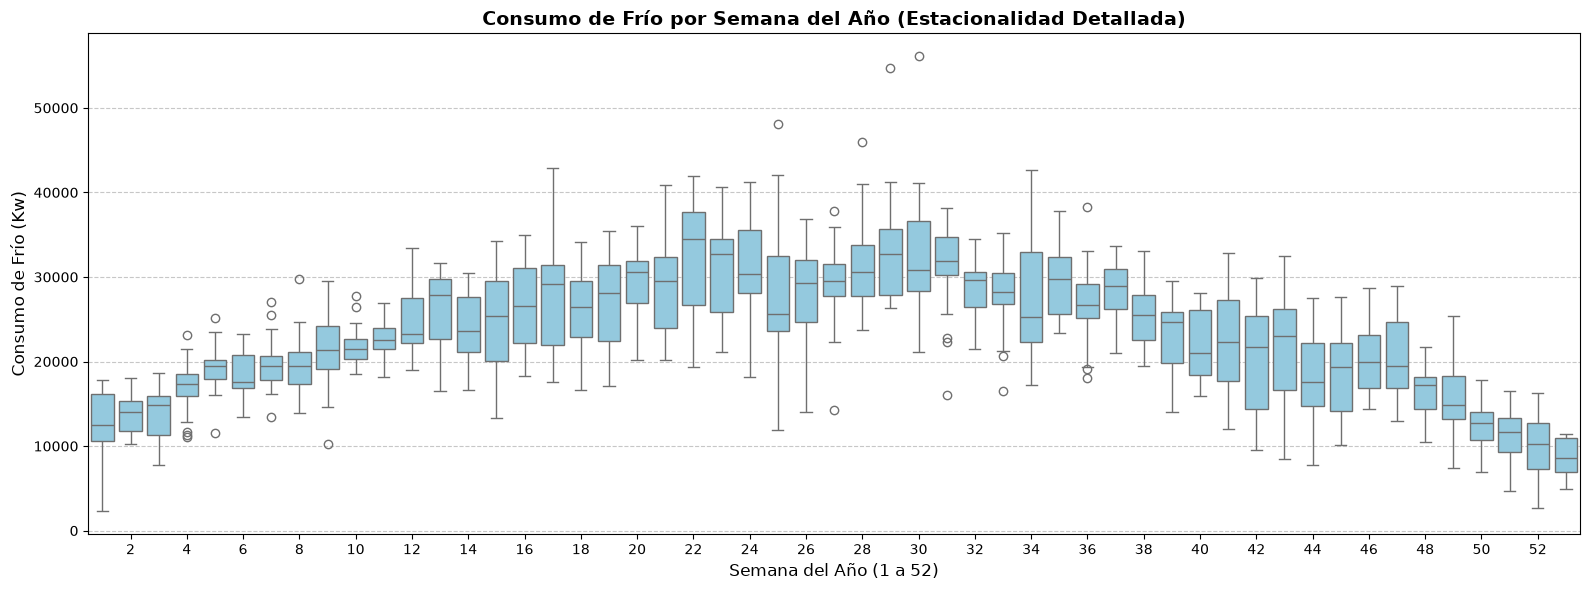

In [36]:
df['Semana_Año'] = df['DIA'].dt.isocalendar().week

plt.figure(figsize=(16, 6))
sns.boxplot(
    x='Semana_Año', 
    y='Frio (Kw) (Consolidado EE)', 
    data=df, 
    color='skyblue'
)

plt.title('Consumo de Frío por Semana del Año (Estacionalidad Detallada)', fontsize=14, fontweight='bold')
plt.xlabel('Semana del Año (1 a 52)', fontsize=12)
plt.ylabel('Consumo de Frío (Kw)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Mostramos solo semanas pares en el eje X para que no se amontone el texto
plt.xticks(ticks=range(1, 53, 2), labels=range(2, 54, 2))
plt.tight_layout()
plt.show()

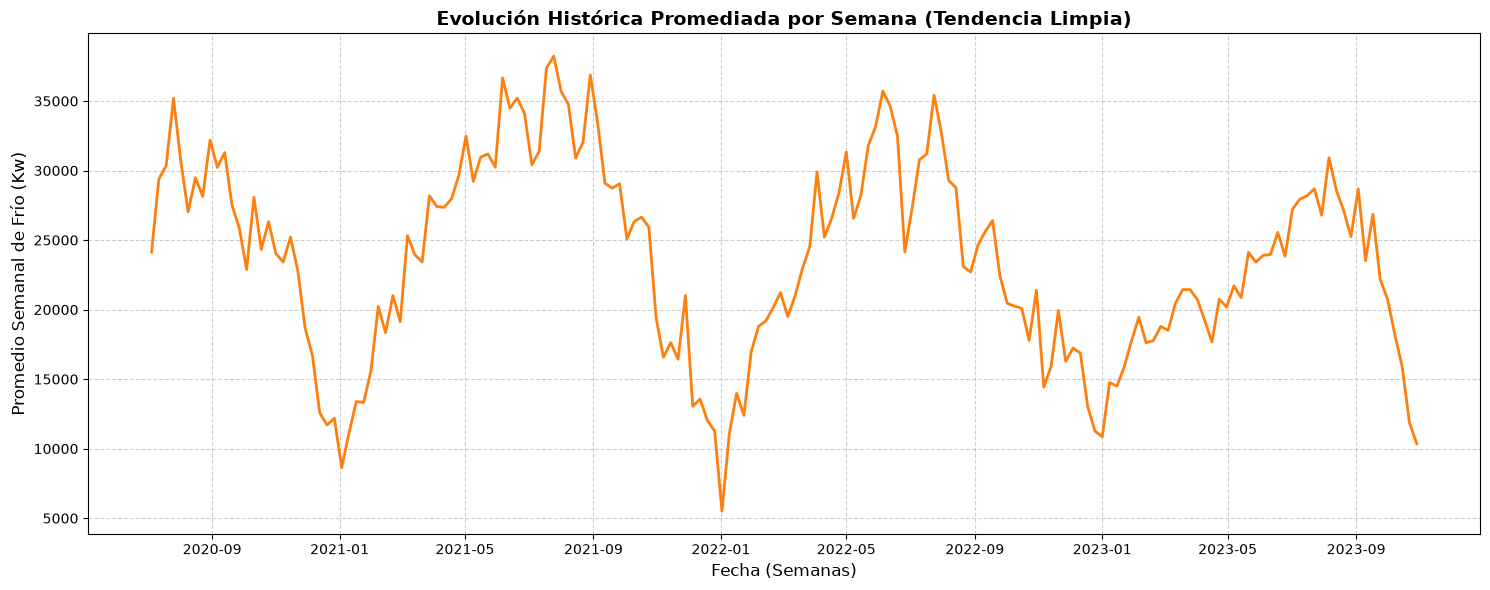

In [37]:
df_temp = df.set_index('DIA')

# Agrupamos por semana ('W') y calculamos el promedio de consumo de esa semana
df_semanal = df_temp['Frio (Kw) (Consolidado EE)'].resample('W').mean()

plt.figure(figsize=(15, 6))
plt.plot(df_semanal.index, df_semanal.values, color='#ff7f0e', linewidth=2)

plt.title('Evolución Histórica Promediada por Semana (Tendencia Limpia)', fontsize=14, fontweight='bold')
plt.xlabel('Fecha (Semanas)', fontsize=12)
plt.ylabel('Promedio Semanal de Frío (Kw)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Correlaciones con el target

Calculamos Pearson entre el target y cada columna de `columnas_analisis` (sin valores imposibles, sin duplicadas y sin metas o KPI derivados), con al menos 100 días en común. Mostramos también Spearman, que mide relaciones monótonas y es menos sensible a valores extremos. Las columnas de calendario creadas para los gráficos (`Mes`, `Año`, etc.) no entran en el ranking.

Las 15 variables más correlacionadas con el target:


,Pearson,Spearman,Días con dato
Frio (Kw) (Consolidado EE),0.840,0.853,1169
Servicios (Kw) (Consolidado EE),0.811,0.829,1169
Agua Planta (Hl) (Consolidado Agua),0.706,0.726,1169
Planta de agua (Hl) (Consolidado Agua),0.698,0.719,1169
KW Cond 5. 6 y 9 (Totalizadores Energia),0.678,0.698,1169
Produccion (Hl) (Consolidado Agua),0.663,0.678,1169
KW Trafo 11 (Totalizadores Energia),0.645,0.631,1169
KW Trafo 10 (Totalizadores Energia),0.634,0.639,1169
Agua Cond REC (Totalizadores Agua),0.607,0.646,1169
KW Mycom 7 (Totalizadores Energia),0.597,0.642,1169


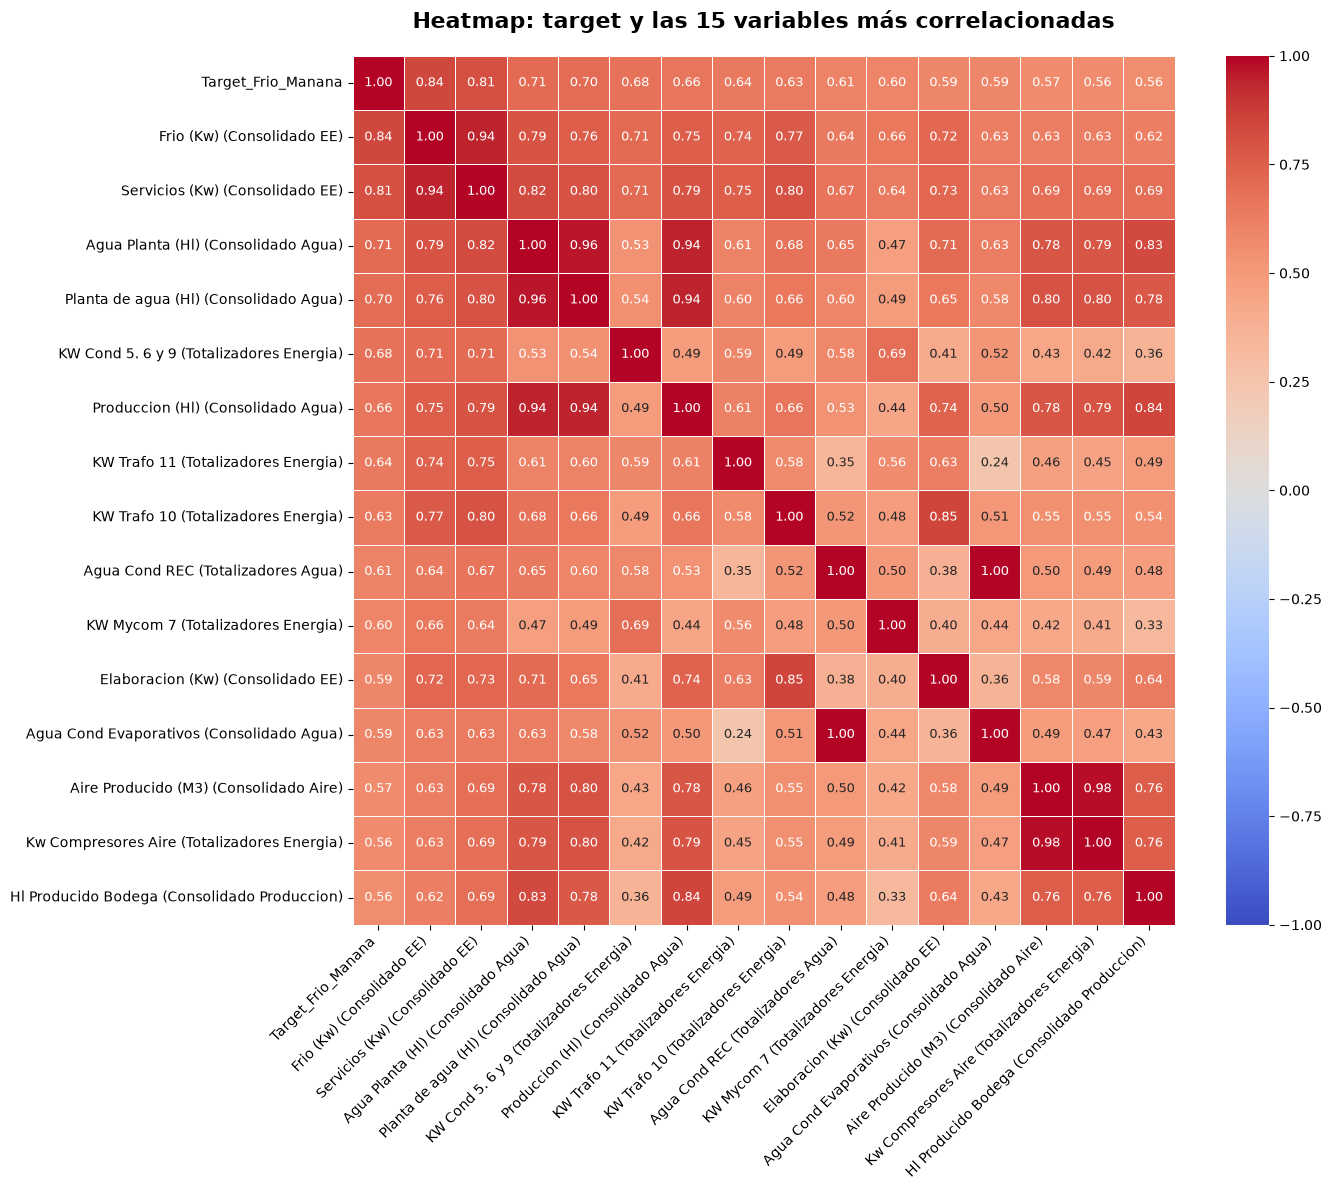

In [38]:
columnas_correlacion = [*columnas_analisis, 'Target_Frio_Manana']
matriz_completa = df[columnas_correlacion].corr(min_periods=100)
correlaciones_target = matriz_completa['Target_Frio_Manana'].drop('Target_Frio_Manana').dropna()
top_15_variables = correlaciones_target.abs().sort_values(ascending=False).head(15).index

spearman_target = df[[*top_15_variables, 'Target_Frio_Manana']].corr(method='spearman')['Target_Frio_Manana']
tabla_top_15 = pd.DataFrame({
    'Pearson': correlaciones_target[top_15_variables],
    'Spearman': spearman_target[top_15_variables],
    'Días con dato': df[top_15_variables].notna().sum(),
})
print('Las 15 variables más correlacionadas con el target:')
display(tabla_top_15.round(3))

df_top_15 = df[['Target_Frio_Manana', *top_15_variables]]
matriz_top_15 = df_top_15.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(
    matriz_top_15,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    annot_kws={'size': 9}
)
plt.title('Heatmap: target y las 15 variables más correlacionadas', fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

In [39]:
X_top = df[list(top_15_variables)]
matriz_predictores = X_top.corr().abs()

print('--- 1. PARES CON ALTA CORRELACIÓN (> 0.80) ---')
pares_altos = sorted(
    ((a, b, matriz_predictores.loc[a, b])
     for posicion, a in enumerate(matriz_predictores.columns)
     for b in matriz_predictores.columns[posicion + 1:]
     if matriz_predictores.loc[a, b] > 0.80),
    key=lambda par: par[2], reverse=True,
)
print(f'Pares encontrados: {len(pares_altos)}. Mostramos los 20 más altos.')
for a, b, valor in pares_altos[:20]:
    print(f"'{a}' y '{b}': {valor:.2f}")
if not pares_altos:
    print('No hay pares con correlación mayor a 0.80.')

# El VIF no se puede calcular con columnas casi idénticas (la matriz queda singular).
# Recorremos el top 15 de mayor a menor correlación con el target y descartamos
# las que repiten en más de 0.95 a una variable ya elegida.
seleccion_vif, descartadas_vif = [], []
for columna in correlaciones_target[top_15_variables].abs().sort_values(ascending=False).index:
    repetida = next((elegida for elegida in seleccion_vif if matriz_predictores.loc[columna, elegida] > 0.95), None)
    if repetida:
        descartadas_vif.append((columna, repetida))
    else:
        seleccion_vif.append(columna)

print('\n--- 2. FACTOR DE INFLACIÓN DE LA VARIANZA (VIF) ---')
for columna, repetida in descartadas_vif:
    print(f"Fuera del VIF por repetir a '{repetida}': '{columna}'")
X_vif = df[seleccion_vif].dropna()
print(f'Días completos para el VIF: {len(X_vif)} | variables: {len(seleccion_vif)}')
if len(X_vif) > len(seleccion_vif) + 1:
    X_con_constante = sm.add_constant(X_vif)
    vif_data = pd.DataFrame({
        'Variable': seleccion_vif,
        'VIF': [variance_inflation_factor(X_con_constante.values, i) for i in range(1, X_con_constante.shape[1])],
    }).sort_values('VIF', ascending=False)
    print(vif_data.to_string(index=False))
    print('Un VIF mayor a 10 indica que la variable se puede reconstruir casi por completo con las demás.')
else:
    print('No hay suficientes días completos para estimar el VIF.')

--- 1. PARES CON ALTA CORRELACIÓN (> 0.80) ---
Pares encontrados: 13. Mostramos los 20 más altos.
'Agua Cond REC (Totalizadores Agua)' y 'Agua Cond Evaporativos (Consolidado Agua)': 1.00
'Aire Producido (M3) (Consolidado Aire)' y 'Kw Compresores Aire (Totalizadores Energia)': 0.98
'Agua Planta (Hl) (Consolidado Agua)' y 'Planta de agua (Hl) (Consolidado Agua)': 0.96
'Agua Planta (Hl) (Consolidado Agua)' y 'Produccion (Hl) (Consolidado Agua)': 0.94
'Frio (Kw) (Consolidado EE)' y 'Servicios (Kw) (Consolidado EE)': 0.94
'Planta de agua (Hl) (Consolidado Agua)' y 'Produccion (Hl) (Consolidado Agua)': 0.94
'KW Trafo 10 (Totalizadores Energia)' y 'Elaboracion (Kw) (Consolidado EE)': 0.85
'Produccion (Hl) (Consolidado Agua)' y 'Hl Producido Bodega (Consolidado Produccion)': 0.84
'Agua Planta (Hl) (Consolidado Agua)' y 'Hl Producido Bodega (Consolidado Produccion)': 0.83
'Servicios (Kw) (Consolidado EE)' y 'Agua Planta (Hl) (Consolidado Agua)': 0.82
'Planta de agua (Hl) (Consolidado Agua)' y '

### Variables casi idénticas al Frío del mismo día

Buscamos columnas con |r| > 0.98 respecto de `Frio (Kw)` del mismo día. No son fuga de información: se conocen al cierre del día `D` y el target es el día `D+1`. Habría fuga si usáramos sus valores de `D+1`, o si una columna con |r| > 0.98 respecto del **target** apareciera en el mismo día, porque eso indicaría que contiene el consumo de mañana. Lo que sí generan es redundancia: no agregan información al Frío de hoy e inflan la multicolinealidad.

In [40]:
corr_frio_mismo_dia = df[columnas_analisis].corrwith(df[col_frio]).drop(col_frio, errors='ignore').dropna()
casi_copias = corr_frio_mismo_dia[corr_frio_mismo_dia.abs().gt(0.98)].sort_values(key=np.abs, ascending=False)
print(f'Columnas con |r| > 0.98 respecto del Frío del mismo día: {len(casi_copias)}')
if not casi_copias.empty:
    display(pd.DataFrame({
        'r con Frío del día D': casi_copias,
        'r con el target (D+1)': correlaciones_target.reindex(casi_copias.index),
    }).round(3))
print(f'Referencia: r entre el Frío del día D y el target = {correlaciones_target.get(col_frio, np.nan):.3f}')

sospechosas_fuga = correlaciones_target[correlaciones_target.abs().gt(0.98)]
print(f'Columnas con |r| > 0.98 respecto del target: {len(sospechosas_fuga)}')
if not sospechosas_fuga.empty:
    print('Revisar: estas columnas podrían contener información del día siguiente.')
    print(sospechosas_fuga.round(3).to_string())

Columnas con |r| > 0.98 respecto del Frío del mismo día: 0
Referencia: r entre el Frío del día D y el target = 0.840
Columnas con |r| > 0.98 respecto del target: 0


### Distribución del target

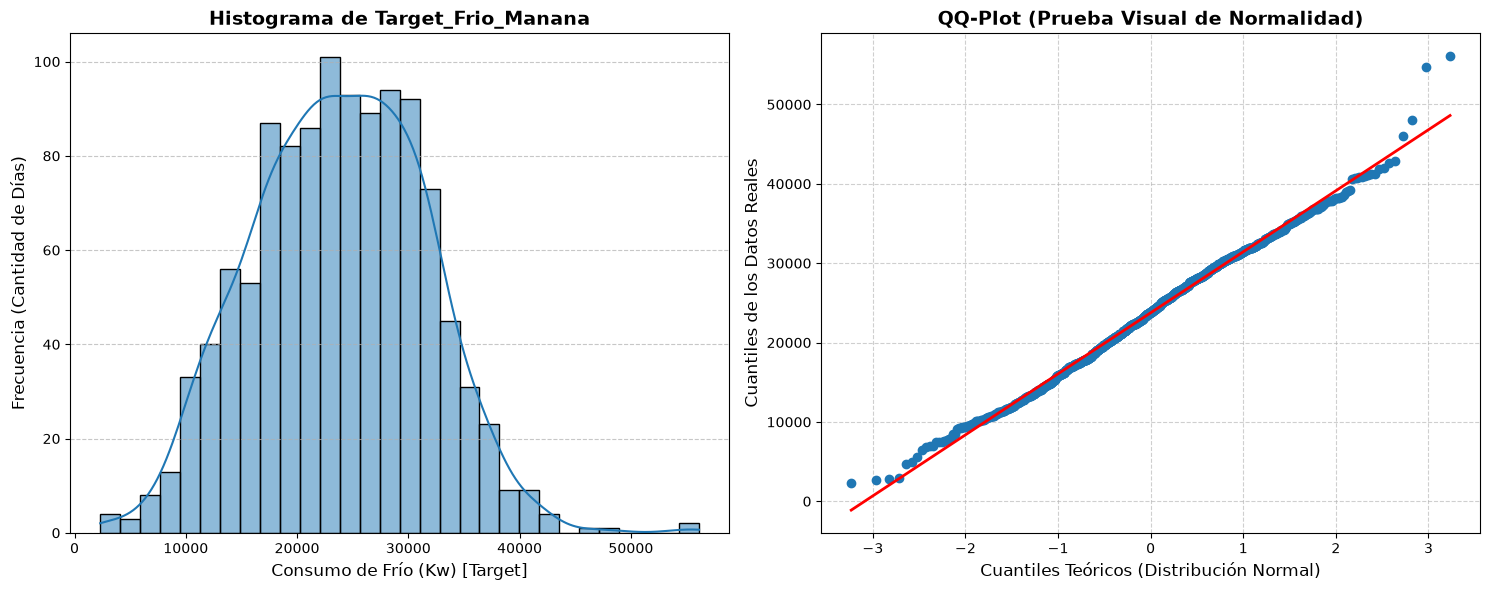

In [41]:
target = df['Target_Frio_Manana'].dropna()

# Crear un lienzo con 2 subgráficos (1 fila, 2 columnas)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# ---------------------------------------------------------
# 1. HISTOGRAMA CON CURVA DE DENSIDAD (KDE)
# ---------------------------------------------------------
sns.histplot(target, kde=True, color='#1f77b4', ax=ax1, bins=30)
ax1.set_title('Histograma de Target_Frio_Manana', fontsize=14, fontweight='bold')
ax1.set_xlabel('Consumo de Frío (Kw) [Target]', fontsize=12)
ax1.set_ylabel('Frecuencia (Cantidad de Días)', fontsize=12)
ax1.grid(axis='y', linestyle='--', alpha=0.7)

# ---------------------------------------------------------
# 2. QQ-PLOT (Gráfico Cuantil-Cuantil)
# ---------------------------------------------------------
# stats.probplot compara nuestra variable contra una distribución normal teórica ("norm")
stats.probplot(target, dist="norm", plot=ax2)

# Personalización de colores del QQ-Plot para que coincida con el estilo
ax2.get_lines()[0].set_markerfacecolor('#1f77b4') # Puntos azules
ax2.get_lines()[0].set_markeredgecolor('#1f77b4') 
ax2.get_lines()[1].set_color('red')               # Línea de referencia roja
ax2.get_lines()[1].set_linewidth(2)

ax2.set_title('QQ-Plot (Prueba Visual de Normalidad)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Cuantiles Teóricos (Distribución Normal)', fontsize=12)
ax2.set_ylabel('Cuantiles de los Datos Reales', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.6)

# Ajustar márgenes y mostrar
plt.tight_layout()
plt.show()

### Target contra las 5 variables más correlacionadas

Las cinco variables salen del ranking calculado arriba, así que el gráfico se actualiza solo si cambia la limpieza.

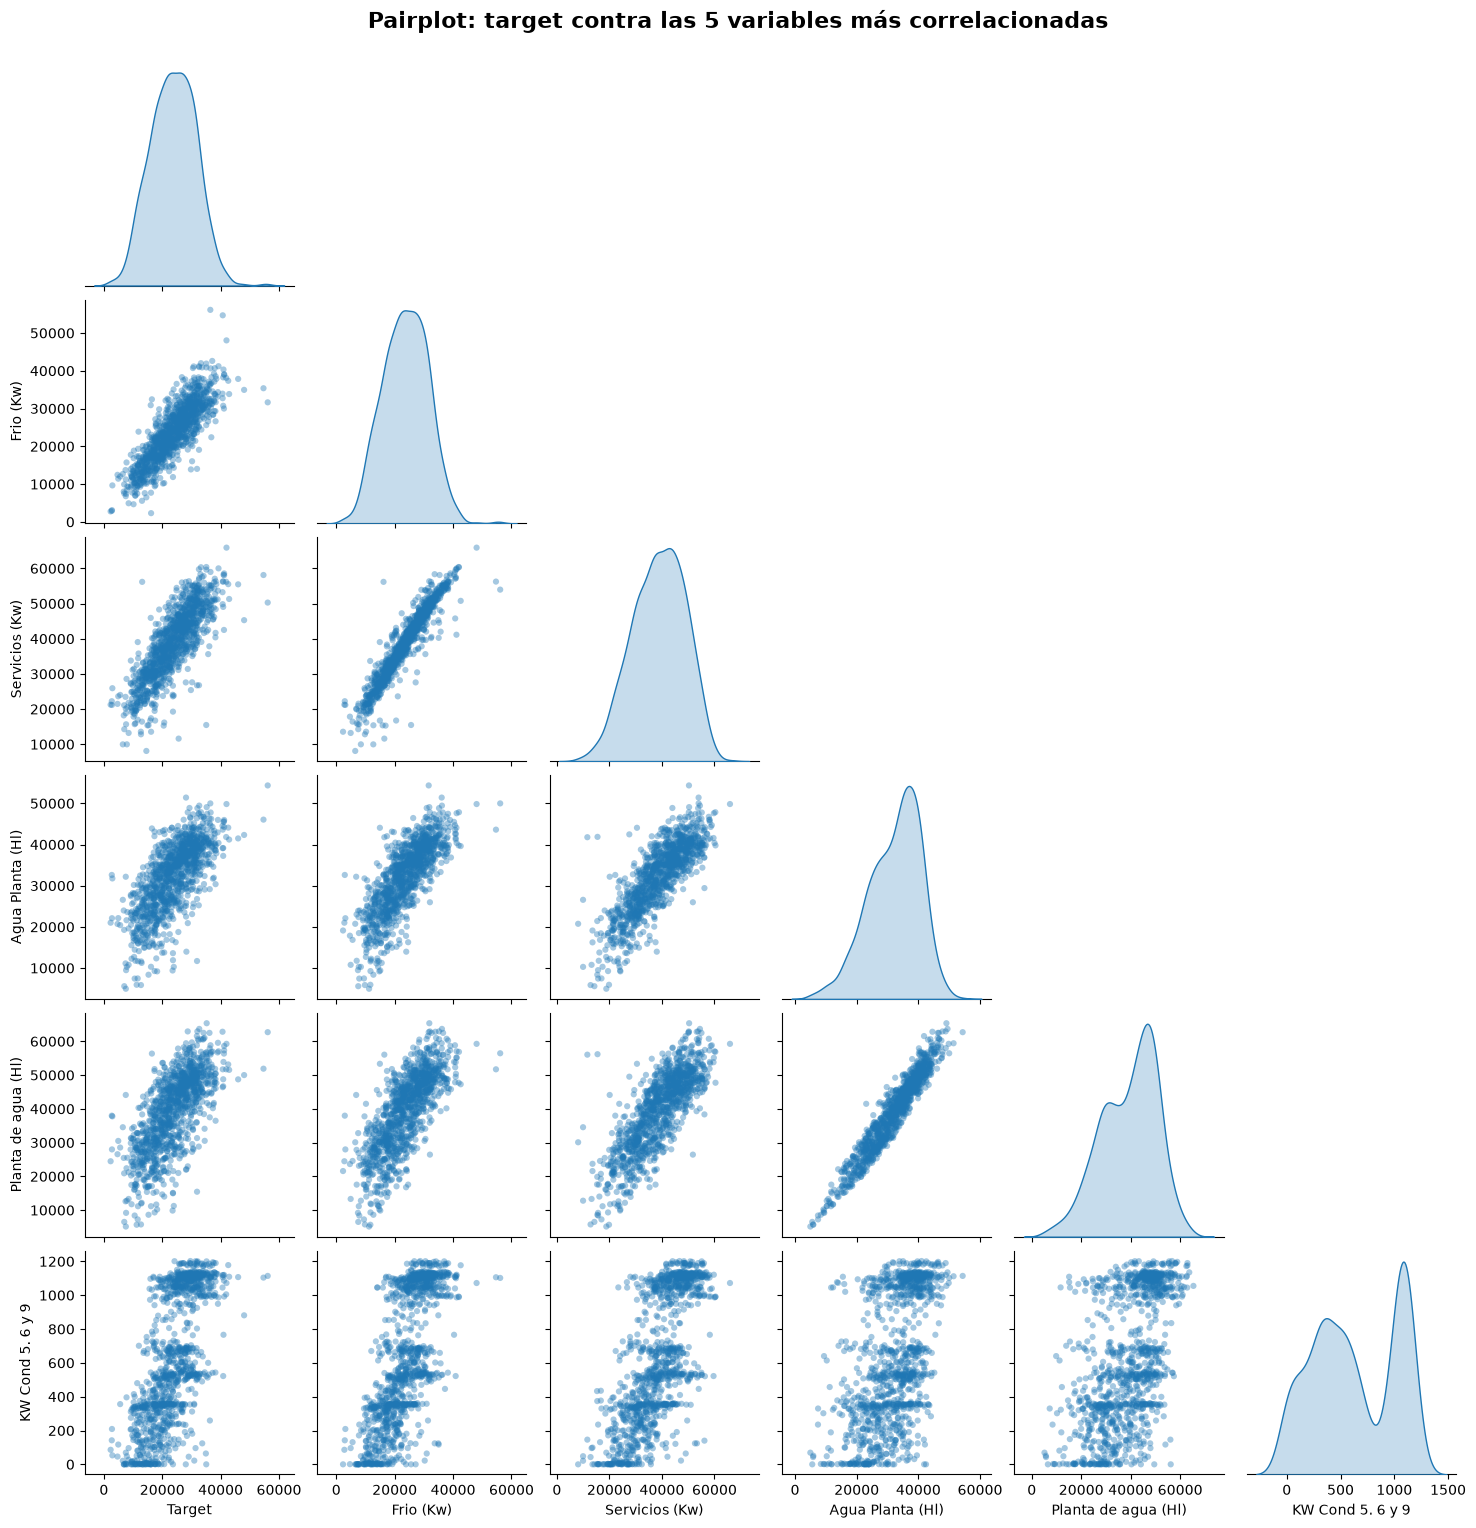

In [42]:
top_5_variables = list(top_15_variables[:5])
columnas_pairplot = ['Target_Frio_Manana', *top_5_variables]

nombres_cortos = {'Target_Frio_Manana': 'Target'}
for columna in top_5_variables:
    base = columna.rsplit(' (', 1)[0][:24]
    nombres_cortos[columna] = base if base not in nombres_cortos.values() else columna[:30]

df_pairplot = df[columnas_pairplot].dropna().rename(columns=nombres_cortos)
g = sns.pairplot(
    df_pairplot,
    diag_kind='kde',
    corner=True,
    plot_kws={'alpha': 0.4, 's': 20, 'edgecolor': 'none'}
)
g.fig.suptitle('Pairplot: target contra las 5 variables más correlacionadas', y=1.02, fontsize=16, fontweight='bold')
plt.show()

### Consumo eléctrico por área de la planta

Usamos los kW diarios por área de `Consolidado EE`, ya sin valores imposibles. La tabla muestra la mediana diaria de cada área, su peso sobre el consumo total de la planta y su correlación con el target. Algunas áreas pueden estar contenidas en otras (por ejemplo, `Servicios` agrupa equipos de frío, aire y calderas), por eso los porcentajes no tienen que sumar 100. El segundo gráfico compara la estacionalidad de cada área dividiendo la mediana mensual por la mediana anual del área.

,Mediana diaria (kW),Peso sobre la planta (%),Correlación con el target
Servicios,39085.00,58.47,0.81
Sala Maq,26875.00,40.20,0.34
Frio,23731.00,35.50,0.84
Envasado,16346.00,24.45,0.52
Elaboracion,7149.00,10.69,0.59
Aire,6550.00,9.80,0.54
Bodega,6108.19,9.14,0.53
Cocina,1972.00,2.95,0.36
Efluentes,845.50,1.26,0.29
Calderas,504.00,0.75,0.17


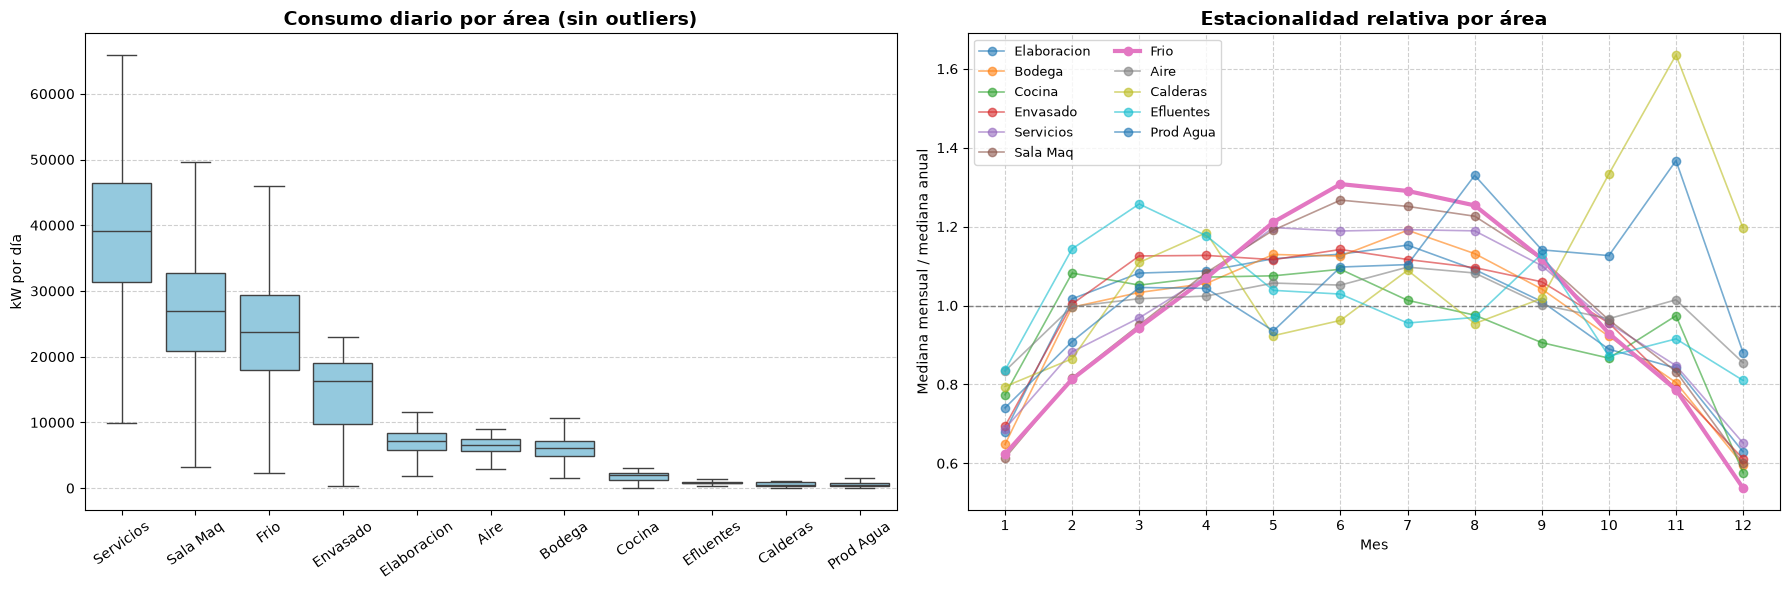

In [43]:
areas_ee = ['Elaboracion', 'Bodega', 'Cocina', 'Envasado', 'Servicios', 'Sala Maq',
            'Frio', 'Aire', 'Calderas', 'Efluentes', 'Prod Agua']
columnas_areas = {area: f'{area} (Kw) (Consolidado EE)' for area in areas_ee
                  if f'{area} (Kw) (Consolidado EE)' in df.columns}
consumo_areas = df[list(columnas_areas.values())].rename(columns={v: k for k, v in columnas_areas.items()})
consumo_planta = df['Planta (Kw) (Consolidado EE)'].median()

resumen_areas = pd.DataFrame({
    'Mediana diaria (kW)': consumo_areas.median(),
    'Peso sobre la planta (%)': consumo_areas.median() / consumo_planta * 100,
    'Correlación con el target': consumo_areas.corrwith(df['Target_Frio_Manana']),
}).sort_values('Mediana diaria (kW)', ascending=False)
display(resumen_areas.round(2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))
sns.boxplot(data=consumo_areas[resumen_areas.index], ax=ax1, color='skyblue', showfliers=False)
ax1.set_title('Consumo diario por área (sin outliers)', fontsize=14, fontweight='bold')
ax1.set_ylabel('kW por día')
ax1.tick_params(axis='x', rotation=35)
ax1.grid(axis='y', linestyle='--', alpha=0.6)

estacionalidad_areas = consumo_areas.groupby(df['DIA'].dt.month).median() / consumo_areas.median()
for area in estacionalidad_areas.columns:
    destacar = area == 'Frio'
    ax2.plot(estacionalidad_areas.index, estacionalidad_areas[area], marker='o',
             linewidth=3 if destacar else 1.2, alpha=1 if destacar else 0.6, label=area)
ax2.axhline(1, color='gray', linestyle='--', linewidth=1)
ax2.set_xticks(range(1, 13))
ax2.set_xlabel('Mes')
ax2.set_ylabel('Mediana mensual / mediana anual')
ax2.set_title('Estacionalidad relativa por área', fontsize=14, fontweight='bold')
ax2.legend(ncol=2, fontsize=9)
ax2.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Indicadores por hectolitro (KPI)

Como complemento, comparamos los KPI de consumo por hectolitro de cada área. Los mostramos sin outliers porque los días con producción cercana a cero generan cocientes extremos. Son variables derivadas de otras columnas y no entran en la selección de features.

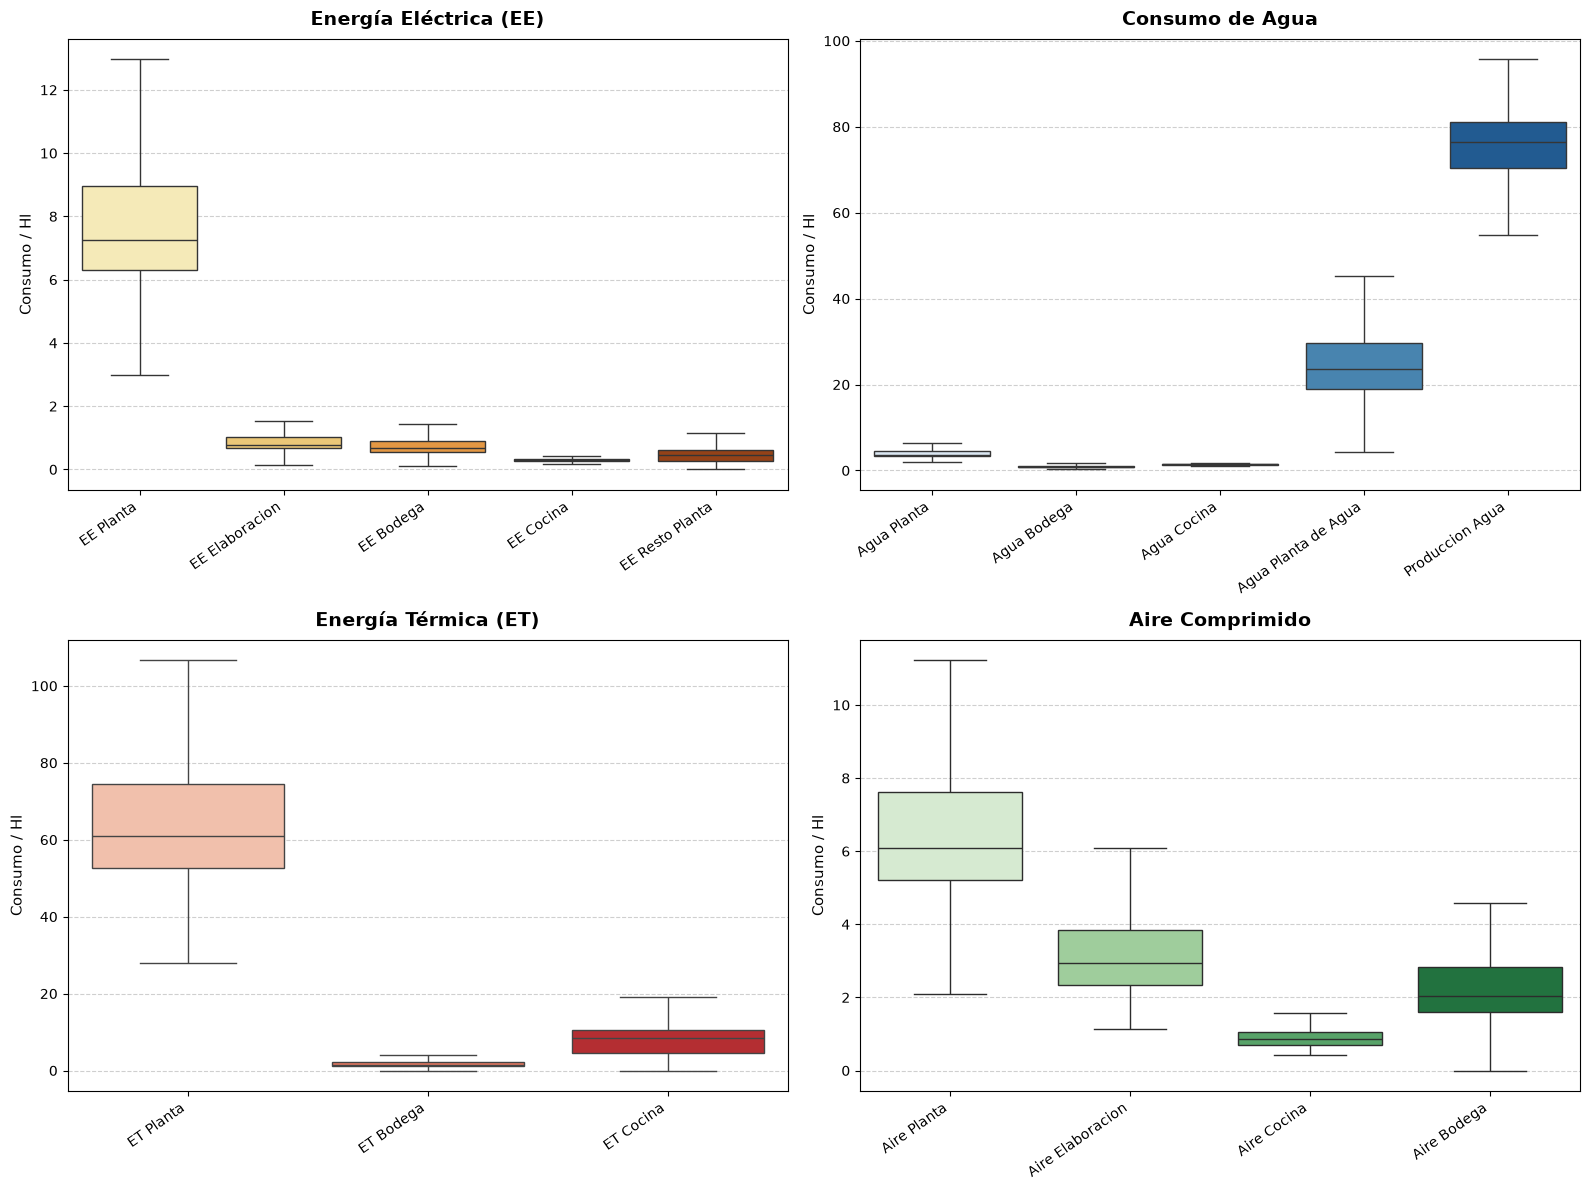

In [44]:
cols_ee = [
    'EE Planta / Hl (Consolidado KPI)',
    'EE Elaboracion / Hl (Consolidado KPI)',
    'EE Bodega / Hl (Consolidado KPI)',
    'EE Cocina / Hl (Consolidado KPI)',
    'EE Resto Planta / Hl (Consolidado KPI)'
]

cols_agua = [
    'Agua Planta / Hl (Consolidado KPI)',
    'Agua Bodega / Hl (Consolidado KPI)',
    'Agua Cocina / Hl (Consolidado KPI)',
    'Agua Planta de Agua/Hl (Consolidado KPI)',
    'Produccion Agua / Hl (Consolidado KPI)'
]

cols_et = [
    'ET Planta / Hl (Consolidado KPI)',
    'ET Bodega/Hl (Consolidado KPI)',
    'ET Cocina/Hl (Consolidado KPI)'
]

cols_aire = [
    'Aire Planta / Hl (Consolidado KPI)',
    'Aire Elaboracion / Hl (Consolidado KPI)',
    'Aire Cocina / Hl (Consolidado KPI)',
    'Aire Bodega / Hl (Consolidado KPI)'
]

# 2. Creamos un lienzo grande con 4 subgráficos (2 filas y 2 columnas)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 3. Agrupamos la información para iterar y graficar fácilmente
categorias = [
    ('Energía Eléctrica (EE)', cols_ee, axes[0, 0], 'YlOrBr'), # Amarillo/Naranja
    ('Consumo de Agua', cols_agua, axes[0, 1], 'Blues'),       # Azul
    ('Energía Térmica (ET)', cols_et, axes[1, 0], 'Reds'),     # Rojo
    ('Aire Comprimido', cols_aire, axes[1, 1], 'Greens')       # Verde
]

# 4. Generamos cada uno de los 4 gráficos
for titulo, columnas, ax, paleta in categorias:
    
    # Graficar usando solo las columnas correspondientes
    sns.boxplot(data=df[columnas], ax=ax, palette=paleta, showfliers=False)
    
    # Configuración de títulos
    ax.set_title(titulo, fontsize=14, fontweight='bold', pad=10)
    ax.set_ylabel('Consumo / Hl', fontsize=11)
    
    # Acortamos los nombres largos del eje X:
    # Nos quedamos solo con la parte antes de la barra "/"
    nombres_cortos = [col.split(' /')[0].split('/')[0] for col in columnas]
    
    ax.set_xticks(range(len(columnas)))
    ax.set_xticklabels(nombres_cortos, rotation=35, ha='right', fontsize=10)
    
    # Grilla de fondo para facilitar la lectura
    ax.grid(axis='y', linestyle='--', alpha=0.6)

# 5. Ajustar márgenes para que nada se superponga y mostrar
plt.tight_layout()
plt.show()

### Validación de calidad

Este diagnóstico usa `df_final`, la tabla que resulta de unir las hojas. Por fecha, cuenta las filas y verifica cuáles de las 24 horas esperadas (`00:00` a `23:00`) y el cierre (`23:59:00`) están presentes. Una hora repetida o fuera de la grilla puede hacer que un día tenga 25 filas aunque le falte una lectura esperada. También señala fechas sin registros entre el primer y el último día del dataset y si el cierre contiene Frío. La cobertura se refiere a la tabla unificada; una fila presente puede tener columnas vacías.

Para `Frio (Kw)` de `Consolidado EE`, revisamos por separado valores negativos, infinitos y valores de al menos un millón. El millón se usa como umbral de revisión por la escala de los errores descrita en la consigna. El IQR del bloque anterior detecta valores poco comunes en la muestra, que pueden ser mediciones reales. Este diagnóstico solo lista casos para revisar.


In [45]:
def validar_calidad_eda(tabla):
    columna_frio = 'Frio (Kw) (Consolidado EE)'
    cierre = '23:59:00'
    horas_requeridas = tuple(f'{hora:02d}:00:00' for hora in range(24)) + (cierre,)
    conjunto_esperado = set(horas_requeridas)
    lecturas = tabla[['DIA', 'HORA', columna_frio]].copy()
    lecturas['DIA'] = pd.to_datetime(lecturas['DIA'], errors='coerce').dt.normalize()
    lecturas['Hora normalizada'] = lecturas['HORA'].map(normalizar_hora)
    lecturas[columna_frio] = pd.to_numeric(lecturas[columna_frio], errors='coerce')
    sin_fecha = lecturas['DIA'].isna().sum()
    con_fecha = lecturas.dropna(subset=['DIA'])
    if con_fecha.empty:
        raise ValueError('La tabla unificada no contiene fechas válidas.')

    cobertura = []
    for fecha, filas in con_fecha.groupby('DIA'):
        horas = filas['Hora normalizada']
        presentes = set(horas.dropna()) & conjunto_esperado
        frio_cierre = filas.loc[horas.eq(cierre), columna_frio]
        cobertura.append({
            'DIA': fecha,
            'Filas': len(filas),
            'Horas esperadas presentes': len(presentes),
            'Horas esperadas faltantes': tuple(h for h in horas_requeridas if h not in presentes),
            'Filas fuera de grilla': int((~horas.isin(conjunto_esperado)).sum()),
            'Filas repetidas en horas esperadas': int(horas.isin(conjunto_esperado).sum()) - len(presentes),
            'Tiene cierre': cierre in presentes,
            'Cierre con Frío en rango': bool((np.isfinite(frio_cierre) & frio_cierre.ge(0) & frio_cierre.lt(1_000_000)).any()),
        })

    calidad_diaria = pd.DataFrame(cobertura).set_index('DIA')
    calendario = pd.date_range(calidad_diaria.index.min(), calidad_diaria.index.max())
    fechas_sin_registros = calendario.difference(calidad_diaria.index)
    revisar = calidad_diaria.loc[
        calidad_diaria['Filas'].gt(25)
        | calidad_diaria['Horas esperadas presentes'].lt(25)
        | calidad_diaria['Filas fuera de grilla'].gt(0)
        | calidad_diaria['Filas repetidas en horas esperadas'].gt(0)
        | ~calidad_diaria['Cierre con Frío en rango']
    ]

    frio = lecturas[columna_frio]
    motivos = pd.Series(np.select(
        [np.isinf(frio), frio.lt(0), frio.ge(1_000_000)],
        ['Infinito', 'Negativo', 'Un millón o más'], default=''
    ), index=lecturas.index)
    frio_para_revisar = lecturas.loc[motivos.ne(''), ['DIA', 'HORA', columna_frio]].assign(Motivo=motivos)

    print(f'Fechas con registros: {len(calidad_diaria)}')
    print(f'Fechas sin registros dentro del período: {len(fechas_sin_registros)}')
    print(f'Filas sin fecha válida: {sin_fecha}')
    print(f'Fechas con más de 25 filas tras la unión: {calidad_diaria["Filas"].gt(25).sum()}')
    print(f'Fechas con horarios esperados faltantes: {calidad_diaria["Horas esperadas presentes"].lt(25).sum()}')
    print(f'Fechas sin fila de cierre: {(~calidad_diaria["Tiene cierre"]).sum()}')
    sin_frio = calidad_diaria['Tiene cierre'] & ~calidad_diaria['Cierre con Frío en rango']
    print(f'Fechas con fila de cierre pero sin Frío en rango: {sin_frio.sum()}')
    if not revisar.empty:
        display(revisar)
    print(f'Lecturas de Frío fuera de rango: {len(frio_para_revisar)}')
    if not frio_para_revisar.empty:
        display(frio_para_revisar)
    return calidad_diaria, fechas_sin_registros, frio_para_revisar


calidad_diaria, fechas_sin_registros, frio_para_revisar = validar_calidad_eda(df_final)


Fechas con registros: 1174
Fechas sin registros dentro del período: 39
Filas sin fecha válida: 1
Fechas con más de 25 filas tras la unión: 11
Fechas con horarios esperados faltantes: 219
Fechas sin fila de cierre: 5
Fechas con fila de cierre pero sin Frío en rango: 0


,Filas,Horas esperadas presentes,Horas esperadas faltantes,Filas fuera de grilla,Filas repetidas en horas esperadas,Tiene cierre,Cierre con Frío en rango
DIA,,,,,,,
2020-07-02,25,24,"(20:00:00,)",1,0,True,True
2020-07-03,25,24,"(22:00:00,)",1,0,True,True
2020-07-04,25,24,"(12:00:00,)",1,0,True,True
2020-07-08,25,24,"(15:00:00,)",1,0,True,True
2020-07-09,25,24,"(03:00:00,)",1,0,True,True
...,...,...,...,...,...,...,...
2023-09-02,25,21,"(09:00:00, 12:00:00, 16:00:00, 23:00:00)",4,0,True,True
2023-09-19,26,25,(),1,0,True,True
2023-09-20,26,25,(),1,0,True,True


Lecturas de Frío fuera de rango: 3


,DIA,HORA,Frio (Kw) (Consolidado EE),Motivo
5184,2021-01-31,11:00:00,3.277128e+16,Un millón o más
7164,2021-04-22,16:00:00,3.277128e+16,Un millón o más
8374,2021-06-12,01:00:00,4.111695e+06,Un millón o más


### Resumen numérico y subconjunto de features

In [46]:
objetivo = df['Target_Frio_Manana'].dropna()
_, p_normalidad = stats.normaltest(objetivo)

print('=== RESUMEN NUMÉRICO DEL EDA ===')
print(f'Días con cierre: {len(df)} | días con target observable: {len(objetivo)}')
print(f'Columnas de medición: {len(columnas_medicion)} | columnas para el análisis: {len(columnas_analisis)}')
print(f'Valores imposibles reemplazados: {conteo_imposibles.sum()} (Frío: {conteo_imposibles.get(col_frio, 0)})')
print(f'Días en que Frío no se reinició: {len(fechas_frio_sin_reinicio)}')
print(f'Target: media {objetivo.mean():,.0f} kW | desvío {objetivo.std():,.0f} kW | '
      f'asimetría {stats.skew(objetivo):.2f} | normalidad (D\'Agostino) p = {p_normalidad:.1e}')
print(f'Autocorrelación del Frío: rezago 1 = {autocorrelacion[1]:.3f} | rezago 7 = {autocorrelacion[7]:.3f}')
print(f'Día de la semana: Kruskal-Wallis p = {p_kruskal:.1e} | amplitud {amplitud_semanal:,.0f} kW | '
      f'η² dentro de la semana {eta2_neto:.3f}')
print(f'Columnas casi idénticas al Frío del mismo día: {len(casi_copias)}')

# Subconjunto de features: relevancia >= 0.30 y sin redundancia > 0.90 dentro del subconjunto.
umbral_relevancia, umbral_redundancia = 0.30, 0.90
relevantes = correlaciones_target[correlaciones_target.abs().ge(umbral_relevancia)]
subconjunto_propuesto = []
for columna in relevantes.abs().sort_values(ascending=False).index:
    if all(abs(matriz_completa.loc[columna, elegida]) <= umbral_redundancia for elegida in subconjunto_propuesto):
        subconjunto_propuesto.append(columna)

print(f'\nSubconjunto propuesto ({len(subconjunto_propuesto)} variables medidas):')
for columna in subconjunto_propuesto:
    print(f'  - {columna}: r = {correlaciones_target[columna]:.3f}')
print('Features a construir en preprocesamiento: rezagos 1-7 y media móvil 7 días del Frío (por fecha), '
      'día de la semana de D+1, mes y temperatura exterior.')

=== RESUMEN NUMÉRICO DEL EDA ===
Días con cierre: 1169 | días con target observable: 1132
Columnas de medición: 447 | columnas para el análisis: 216
Valores imposibles reemplazados: 758 (Frío: 0)
Días en que Frío no se reinició: 1
Target: media 23,747 kW | desvío 7,693 kW | asimetría 0.06 | normalidad (D'Agostino) p = 6.8e-01
Autocorrelación del Frío: rezago 1 = 0.840 | rezago 7 = 0.736
Día de la semana: Kruskal-Wallis p = 4.4e-01 | amplitud 2,018 kW | η² dentro de la semana 0.039
Columnas casi idénticas al Frío del mismo día: 0

Subconjunto propuesto (77 variables medidas):
  - Frio (Kw) (Consolidado EE): r = 0.840
  - Agua Planta (Hl) (Consolidado Agua): r = 0.706
  - KW Cond 5. 6 y 9 (Totalizadores Energia): r = 0.678
  - KW Trafo 11 (Totalizadores Energia): r = 0.645
  - KW Trafo 10 (Totalizadores Energia): r = 0.634
  - Agua Cond REC (Totalizadores Agua): r = 0.607
  - KW Mycom 7 (Totalizadores Energia): r = 0.597
  - Elaboracion (Kw) (Consolidado EE): r = 0.594
  - Aire Producido

## Conclusiones del EDA

Los valores citados corresponden a la corrida sobre los tres Excel registrados en `data/checksums.json`; la celda anterior los recalcula.

**Calidad de los datos**
- Los tres Excel se solapan. Los unimos conservando el valor más reciente de cada celda y recuperando el anterior cuando el reciente falta. En las fechas compartidas, los cierres de Frío difieren en 1 de 488 fechas, y hay 4 cierres que solo el archivo reciente trae válidos (sección 5.0).
- El día se cierra a las 23:59. Entre las 23:00 y las 23:59 se consume una mediana del 4 % del Frío diario, cerca de 1/24; cerrar a las 23:00 dejaría afuera la última hora.
- Los desbordes de los contadores (10¹² a 10¹⁶) y los negativos en acumulados son valores imposibles: 758 valores en 84 columnas quedan como faltantes para que el preprocesamiento los impute con estadísticos de train. Ningún cierre de Frío es imposible; los tres valores de Frío por encima del millón son lecturas horarias, no cierres.
- De 447 columnas de medición quedan 216 para el análisis. El resto son KPI por Hl, metas de gestión, hojas auxiliares, columnas sin nombre, constantes, identificadores, duplicadas entre `Consolidado` y `Totalizadores` o con datos en menos de la mitad de los días.
- Los outliers IQR se conservan: en Frío hay solo 3 cierres fuera de 1,5·IQR y son días posibles.
- Frío no se reinició a medianoche un solo día (2020-07-11); queda en `fechas_frio_sin_reinicio`.
- Hay 39 días sin ninguna medición dentro del período. Los días previos y posteriores a esos huecos (32 de cada uno) consumen dentro del rango habitual para su mes y día de la semana: los posteriores quedan algo por debajo, pero con tan pocos días y tanta dispersión es solo una pista. Esos huecos dejan sin target al día anterior y cortan los rezagos, por eso se calculan por calendario.

**Comportamiento del Frío**
- El target tiene media 23.747 kW y desvío 7.693 kW, es simétrico (asimetría 0,06) y no se rechaza la normalidad (D'Agostino p = 0,68): no hace falta transformarlo.
- La autocorrelación por calendario es la señal más fuerte: 0,84 con el día anterior y baja despacio (0,74 a los 7 días, 0,68 a los 14). No hay un pico en el rezago 7, así que no aparece un ciclo semanal. Los lags y medias móviles tienen que calcularse por fecha y no por fila.
- Hay estacionalidad anual (boxplots mensuales y por semana del año) y diferencias de nivel entre años.
- El día de la semana no tiene un efecto detectable: Kruskal-Wallis p = 0,44, η² = 0,006 (0,039 dentro de cada semana) y fin de semana contra días hábiles p = 0,40. La mayor diferencia entre días, respecto de su propia semana, es de unos 2.000 kW. El boxplot ajustado por mes lo confirma: las medianas de los siete días quedan cerca de cero. No lo priorizamos como feature.

**Correlaciones y redundancia**
- Las más correlacionadas con el target son `Frio (Kw)` del día (r = 0,84) y `Servicios (Kw)` (0,81), seguidas por agua de planta, condensadores y transformadores (0,63 a 0,71).
- Contra la hipótesis inicial, ninguna columna tiene |r| > 0,98 con el Frío del mismo día ni con el target: los medidores individuales del sistema de frío no lo copian, y no hay indicios de fuga.
- Hay grupos redundantes: las dos medidas de agua de planta (0,96), agua de condensadores REC y evaporativos (1,00), aire producido y compresores de aire (0,98), y Frío con Servicios (0,94). Aun quitando las repetidas, el VIF supera 10 en Servicios, Agua Planta, Producción de agua y Frío, así que conviene no usarlas todas juntas en un modelo lineal.

**Subconjunto de features propuesto**
1. Las variables de `subconjunto_propuesto`: correlación con el target de al menos 0.30 y sin otra variable más correlacionada del subconjunto con la que superen 0.90. El umbral deja 77 columnas; la selección final tiene que hacerse con el conjunto de entrenamiento.
2. Rezagos del Frío por calendario (1 a 7 días) y media móvil de 7 días, justificados por la autocorrelación.
3. Mes o semana del año, por la estacionalidad. El día de la semana de `D+1` puede probarse en el modelo, pero el EDA no lo respalda.
4. Temperatura exterior como hipótesis externa: no está en los Excel, pero la carga de un sistema de refrigeración depende del clima.

**Recomendaciones para el preprocesamiento**
- Construir el target y los lags por fecha (`D + 1 día`), como en este notebook.
- Excluir las columnas de `motivos_exclusion` y tratar como faltantes los valores imposibles y los días de `fechas_frio_sin_reinicio`.
- Ajustar imputación, transformaciones y selección de variables solo con el conjunto de entrenamiento.